In [1]:
from tensorflow.python.lib.io import tf_record
from tensorboard.compat.proto.event_pb2 import Event
from collections import defaultdict
import pandas as pd
import numpy as np
from tensorflow.python.lib.io import tf_record
from tensorboard.compat.proto.event_pb2 import Event
from collections import defaultdict
import pandas as pd
import matplotlib.pyplot as plt

def event_aligned_latency_summary(event_file,
                                  pre_steps=200,
                                  post_steps=2000,
                                  jam_threshold=0.999):

    scalars = defaultdict(list)

    for raw in tf_record.tf_record_iterator(event_file):
        event = Event.FromString(raw)
        if not event.summary:
            continue
        for v in event.summary.value:
            if v.HasField("simple_value"):
                scalars[v.tag].append({
                    "step": event.step,
                    "value": v.simple_value,
                })

    lat = pd.DataFrame(scalars["latency/urllc"]).sort_values("step")
    prb = pd.DataFrame(scalars["prb/effective_ratio"]).sort_values("step")

    df = pd.merge_asof(
        lat, prb,
        on="step",
        direction="nearest",
        tolerance=5,
        suffixes=("_lat", "_prb")
    ).dropna()

    df = df.rename(columns={
        "value_lat": "latency_sec",
        "value_prb": "effective_prb_ratio"
    })

    df["jammed"] = df["effective_prb_ratio"] < jam_threshold

    jam_start_idx = df.index[
        (df["jammed"]) & (~df["jammed"].shift(1).fillna(False))
    ].to_numpy()

    aligned = []

    for idx in jam_start_idx:
        s = idx - pre_steps
        e = idx + post_steps
        if s < 0 or e >= len(df):
            continue
        w = df.iloc[s:e].copy()
        w["t_rel"] = np.arange(-pre_steps, post_steps)
        aligned.append(w[["t_rel", "latency_sec"]])

    aligned_df = pd.concat(aligned)

    summary = (
        aligned_df
        .groupby("t_rel")["latency_sec"]
        .mean()
        .reset_index()
    )

    summary["latency_ms"] = summary["latency_sec"] * 1000.0
    return summary


2026-01-17 22:26:24.156268: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-01-17 22:26:24.187016: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-01-17 22:26:24.876707: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
# IDLE_EVENT_FILE = "../tb_logs/res_validator/idle__20260114_104940__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768405780.elahe-LEGION-T7-34IAS10.557366.0"
# RANDOM_EVENT_FILE = "../tb_logs/res_validator/random__20260114_103447__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768404887.elahe-LEGION-T7-34IAS10.555124.0"
# DQN_EVENT_FILE = "../tb_logs/res_validator/xAppResilientDQNAllocator_20260114_145436_step499500__20260114_180159__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768431719.elahe-LEGION-T7-34IAS10.598494.0"

IDLE_EVENT_FILE = "../tb_logs/res_validator/idle__20260115_223343__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768534423.elahe-LEGION-T7-34IAS10.703928.0"
RANDOM_EVENT_FILE = "../tb_logs/res_validator/random__20260115_233825__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768538305.elahe-LEGION-T7-34IAS10.708775.0"
DQN_EVENT_FILE = "../tb_logs/res_validator/xAppResilientDQNAllocator_20260115_234559_final__20260116_093135__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768573895.elahe-LEGION-T7-34IAS10.731660.0"
DQN_EVENT_FILE_2 = "../tb_logs/res_validator/xAppResilientDQNAllocator_20260116_103601_final__20260116_134558__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768589158.elahe-LEGION-T7-34IAS10.749424.0"
DQN_EVENT_FILE_3 = "../tb_logs/res_validator/xAppResilientDQNAllocator_20260117_154509_final__20260117_184115__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768693275.elahe-LEGION-T7-34IAS10.858330.0"
AGGRESSIVE_FILE = "../tb_logs/res_validator/aggressive__20260116_220216__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768618936.elahe-LEGION-T7-34IAS10.792419.0"
idle_summary   = event_aligned_latency_summary(IDLE_EVENT_FILE)
random_summary = event_aligned_latency_summary(RANDOM_EVENT_FILE)
dqn_summary    = event_aligned_latency_summary(DQN_EVENT_FILE)
dqn_summary_2    = event_aligned_latency_summary(DQN_EVENT_FILE_2)
dqn_summary_3    = event_aligned_latency_summary(DQN_EVENT_FILE_3)
aggressive_summary    = event_aligned_latency_summary(AGGRESSIVE_FILE)


Instructions for updating:
Use eager execution and: 
`tf.data.TFRecordDataset(path)`


/tmp/ipykernel_874693/3044924797.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  (df["jammed"]) & (~df["jammed"].shift(1).fillna(False))
/tmp/ipykernel_874693/3044924797.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  (df["jammed"]) & (~df["jammed"].shift(1).fillna(False))
/tmp/ipykernel_874693/3044924797.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_

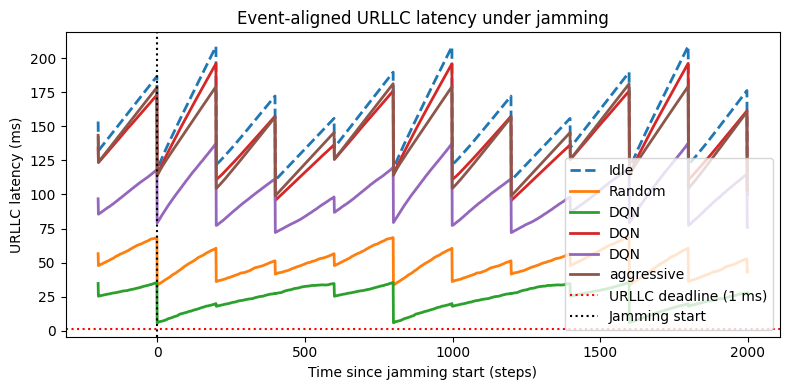

In [3]:
URLLC_DEADLINE_MS = 1.0

plt.figure(figsize=(8, 4))

plt.plot(idle_summary["t_rel"],
         idle_summary["latency_ms"],
         label="Idle",
         linewidth=2,
         linestyle="--")

plt.plot(random_summary["t_rel"],
         random_summary["latency_ms"],
         label="Random",
         linewidth=2)

plt.plot(dqn_summary["t_rel"],
         dqn_summary["latency_ms"],
         label="DQN",
         linewidth=2)

plt.plot(dqn_summary_2["t_rel"],
         dqn_summary_2["latency_ms"],
         label="DQN",
         linewidth=2)

plt.plot(dqn_summary_3["t_rel"],
         dqn_summary_3["latency_ms"],
         label="DQN",
         linewidth=2)

plt.plot(aggressive_summary
["t_rel"],
         aggressive_summary
["latency_ms"],
         label="aggressive",
         linewidth=2)

plt.axhline(URLLC_DEADLINE_MS,
            color="red",
            linestyle=":",
            label="URLLC deadline (1 ms)")

plt.axvline(0,
            color="black",
            linestyle=":",
            label="Jamming start")

plt.xlabel("Time since jamming start (steps)")
plt.ylabel("URLLC latency (ms)")
plt.title("Event-aligned URLLC latency under jamming")
plt.legend()
plt.tight_layout()
plt.show()


## Table section

In [17]:
import numpy as np
import pandas as pd
from tensorflow.python.summary.summary_iterator import summary_iterator
def load_tb_scalars(event_file):
    data = {}
    for e in summary_iterator(event_file):
        if not e.summary.value:
            continue
        step = e.step
        for v in e.summary.value:
            tag = v.tag
            data.setdefault(tag, []).append((step, v.simple_value))
    return {
        tag: pd.DataFrame(vals, columns=["step", "value"]).sort_values("step")
        for tag, vals in data.items()
    }
def infer_jamming(effective_prb_ratio, threshold=0.99):
    return effective_prb_ratio["value"] < threshold
def recovery_time(latency, jamming_mask, latency_threshold, hold_steps=10):
    """
    Time from jamming end until latency stays below threshold for hold_steps
    """
    jam_indices = np.where(jamming_mask)[0]
    if len(jam_indices) == 0:
        return np.nan

    jam_end = jam_indices[-1]

    below = latency["value"].values <= latency_threshold
    for i in range(jam_end + 1, len(below) - hold_steps):
        if np.all(below[i:i+hold_steps]):
            return i - jam_end
    return np.inf


In [50]:
URLLC_DEADLINE_MS = 0.001

def evaluate_policy(tb, latency_threshold):

    latency = tb["latency/urllc"]

    eff_prb = tb["prb/effective_ratio"]
    reserve_prb = tb["obs/reserve_used_prb"]
    embb_thr = tb["throughput/embb_mbps"]
    reward = tb["reward/total"]

    jamming = infer_jamming(eff_prb)

    metrics = {}

    # Performance
    metrics["avg_urllc_latency"] = latency["value"].mean()
    metrics["latency_violation_rate"] = np.mean(latency["value"] > latency_threshold)
    metrics["avg_embb_throughput"] = embb_thr["value"].mean()
    metrics["avg_reward"] = reward["value"].mean()

    # Resilience
    metrics["max_latency_spike"] = latency["value"].max()
    metrics["recovery_time"] = recovery_time(
        latency, jamming, latency_threshold
    )
    metrics["avg_reserve_prb_used"] = reserve_prb["value"].mean()

    return metrics


In [51]:
def plot_latency_cdf(lat_ms, label):
    x = np.sort(lat_ms)
    y = np.arange(len(x)) / len(x)
    plt.plot(x, y, label=label)


In [ ]:
EVENT_FILES = {
    # "Idle": "../tb_logs/res_validator/idle__20260114_104940__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768405780.elahe-LEGION-T7-34IAS10.557366.0",
    # "Random":"../tb_logs/res_validator/random__20260114_103447__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768404887.elahe-LEGION-T7-34IAS10.555124.0",
    # "DQN": "../tb_logs/res_validator/xAppResilientDQNAllocator_20260114_145436_step499500__20260114_180159__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768431719.elahe-LEGION-T7-34IAS10.598494.0"
    #"Random": "path/to/random/events.out.tfevents...",
    #"DQN": "path/to/dqn/events.out.tfevents..."
    "Idle": IDLE_EVENT_FILE,
    "Random": RANDOM_EVENT_FILE,
    "DQN": DQN_EVENT_FILE,
    "AGG": AGGRESSIVE_FILE
}

LATENCY_DEADLINE_MS = 0.001  # <-- adjust to your setup

rows = []

for name, path in EVENT_FILES.items():
    tb = load_tb_scalars(path)
    metrics = evaluate_policy(tb, LATENCY_DEADLINE_MS)
    metrics["policy"] = name
    rows.append(metrics)

df = pd.DataFrame(rows).set_index("policy")


In [53]:
df.to_csv("table_main_results.csv")
print(df)

        avg_urllc_latency  latency_violation_rate  avg_embb_throughput  \
policy                                                                   
Idle              0.15552                0.409750            94.616798   
Random            0.05170                0.203323            95.271696   
DQN               0.02376                0.184324            95.177791   

        avg_reward  max_latency_spike  recovery_time  avg_reserve_prb_used  
policy                                                                      
Idle     -2.480419           2.091662            inf              0.000000  
Random   -1.463533           1.175349            inf             11.702783  
DQN      -0.850496           1.693525            inf             15.373333  


In [54]:
JAM_THRESHOLD = 0.99          # effective PRB ratio < threshold ⇒ jamming
URLLC_LATENCY_DEADLINE = 0.001  # ms (adjust if needed)
RECOVERY_HOLD_STEPS = 10


In [55]:
import numpy as np
import pandas as pd
from tensorflow.python.summary.summary_iterator import summary_iterator
def load_tb_scalars(event_file):
    data = {}
    for e in summary_iterator(event_file):
        if not e.summary.value:
            continue
        for v in e.summary.value:
            data.setdefault(v.tag, []).append((e.step, v.simple_value))
    return {
        tag: pd.DataFrame(vals, columns=["step", "value"]).sort_values("step")
        for tag, vals in data.items()
    }

def align_on_step(dfs):
    base = dfs[0][["step"]].copy()
    for df in dfs:
        base = base.merge(df, on="step", how="inner")
    return base
def jamming_mask(effective_prb_ratio):
    return effective_prb_ratio["value"] < JAM_THRESHOLD


In [56]:
def table_performance(tb):
    return {
        "avg_urllc_latency": tb["latency/urllc"]["value"].mean(),
        "latency_violation_rate": np.mean(
            tb["latency/urllc"]["value"] > URLLC_LATENCY_DEADLINE
        ),
        "avg_embb_throughput": tb["throughput/embb_mbps"]["value"].mean(),
        "avg_reward": tb["reward/total"]["value"].mean(),
    }


In [57]:
def recovery_time(latency, jam_mask):
    jam_idx = np.where(jam_mask)[0]
    if len(jam_idx) == 0:
        return np.nan
    jam_end = jam_idx[-1]

    below = latency["value"].values <= URLLC_LATENCY_DEADLINE
    for i in range(jam_end + 1, len(below) - RECOVERY_HOLD_STEPS):
        if np.all(below[i:i+RECOVERY_HOLD_STEPS]):
            return i - jam_end
    return np.inf


In [58]:
def table_resilience(tb):
    eff = tb["prb/effective_ratio"]
    jam = jamming_mask(eff)
    lat = tb["latency/urllc"]

    return {
        "max_latency_spike": lat["value"].max(),
        "recovery_time": recovery_time(lat, jam),
        "avg_reserve_prb_used": tb["obs/reserve_used_prb"]["value"].mean(),
    }


In [59]:
STATE_TAGS = [
    "state/embb_demand_norm",
    "state/urllc_demand_norm",
    "state/embb_queue_norm",
    "state/urllc_queue_norm",
    "state/embb_thr_norm",
    "state/urllc_thr_norm",
    "state/urllc_lat_excess_norm",
    "state/effective_prb_ratio",
    "state/reserve_used_norm",
]


In [60]:
def table_state_stats(tb):
    row = {}
    for tag in STATE_TAGS:
        v = tb[tag]["value"]
        row[f"{tag}_mean"] = v.mean()
        row[f"{tag}_std"] = v.std()
    return row


In [61]:
def table_jamming_split(tb):
    eff = tb["prb/effective_ratio"]
    jam = jamming_mask(eff)

    lat = tb["latency/urllc"]["value"]
    q = tb["obs/urllc_queue"]["value"]
    r = tb["obs/reserve_used_prb"]["value"]

    return {
        "lat_no_jam": lat[~jam].mean(),
        "lat_jam": lat[jam].mean(),
        "delta_latency": lat[jam].mean() - lat[~jam].mean(),
        "reserve_used_jam": r[jam].mean(),
        "queue_jam": q[jam].mean(),
    }


In [62]:
def table_reserve_efficiency(tb):
    eff = tb["prb/effective_ratio"]
    jam = jamming_mask(eff)
    lat = tb["latency/urllc"]["value"]
    r = tb["obs/reserve_used_prb"]["value"]

    violations = np.mean(lat[jam] > URLLC_LATENCY_DEADLINE)
    return {
        "reserve_used_jam": r[jam].mean(),
        "violation_rate_jam": violations,
        "max_latency_jam": lat[jam].max(),
    }


In [63]:
def table_actions(tb):
    a = tb["action/index"]["value"]
    da = np.abs(np.diff(a))

    return {
        "action_variance": a.var(),
        "action_change_rate": np.mean(da > 0),
        "mean_abs_action_change": da.mean(),
    }


In [64]:
def table_satisfaction(tb):
    return {
        "urllc_sat_capped": tb["satisfaction/URLLC_capped"]["value"].mean(),
        "embb_sat_capped": tb["satisfaction/eMBB_capped"]["value"].mean(),
        "urllc_sat_worst": tb["satisfaction/URLLC_raw"]["value"].min(),
    }


In [65]:
def table_episode(tb):
    r = tb["episode/return"]["value"]
    l = tb["episode/length"]["value"]

    return {
        "return_mean": r.mean(),
        "return_std": r.std(),
        "return_p10": np.percentile(r, 10),
        "episode_length_mean": l.mean(),
    }


In [66]:
def table_correlation(tb):
    eff = tb["prb/effective_ratio"]
    jam = jamming_mask(eff)

    lat = tb["latency/urllc"]["value"][jam]
    q = tb["state/urllc_queue_norm"]["value"][jam]
    r = tb["state/reserve_used_norm"]["value"][jam]

    return {
        "corr_queue_latency": np.corrcoef(q, lat)[0,1],
        "corr_reserve_latency": np.corrcoef(r, lat)[0,1],
    }


In [67]:
def print_table(name, df, float_fmt="{:.3f}"):
    print("\n" + "=" * 80)
    print(f"TABLE: {name.upper()}")
    print("=" * 80)
    print(df.to_string(float_format=lambda x: float_fmt.format(x)))


In [4]:
# EVENTS = {
#     # "Idle": "path/to/idle/events",
#     # "Random": "path/to/random/events",
#     "Idle": "../tb_logs/res_validator/idle__20260114_104940__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768405780.elahe-LEGION-T7-34IAS10.557366.0",
#     "Random":"../tb_logs/res_validator/random__20260114_103447__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768404887.elahe-LEGION-T7-34IAS10.555124.0",
#     "DQN": "../tb_logs/res_validator/xAppResilientDQNAllocator_20260114_145436_step499500__20260114_180159__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768431719.elahe-LEGION-T7-34IAS10.598494.0"
#     #"DQN": "path/to/dqn/events",
    
# }
EVENTS = {
    # "Idle": "../tb_logs/res_validator/idle__20260114_104940__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768405780.elahe-LEGION-T7-34IAS10.557366.0",
    # "Random":"../tb_logs/res_validator/random__20260114_103447__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768404887.elahe-LEGION-T7-34IAS10.555124.0",
    # "DQN": "../tb_logs/res_validator/xAppResilientDQNAllocator_20260114_145436_step499500__20260114_180159__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768431719.elahe-LEGION-T7-34IAS10.598494.0"
    #"Random": "path/to/random/events.out.tfevents...",
    #"DQN": "path/to/dqn/events.out.tfevents..."
    "Idle": IDLE_EVENT_FILE,
    "Random": RANDOM_EVENT_FILE,
    "DQN": DQN_EVENT_FILE,
    "AGRR": AGGRESSIVE_FILE
}

LATENCY_DEADLINE_MS = 0.001  # <-- adjust to your setup




tables = {
    "performance": [],
    "resilience": [],
    "state_stats": [],
    "jamming_split": [],
    "reserve_efficiency": [],
    "actions": [],
    "satisfaction": [],
    "episode": [],
    "correlation": [],
}

for name, path in EVENTS.items():
    tb = load_tb_scalars(path)

    for key, fn in [
        ("performance", table_performance),
        ("resilience", table_resilience),
        ("state_stats", table_state_stats),
        ("jamming_split", table_jamming_split),
        ("reserve_efficiency", table_reserve_efficiency),
        ("actions", table_actions),
        ("satisfaction", table_satisfaction),
        ("episode", table_episode),
        ("correlation", table_correlation),
    ]:
        row = fn(tb)
        row["policy"] = name
        tables[key].append(row)

for k, rows in tables.items():
    df = pd.DataFrame(rows).set_index("policy")
    df.to_csv(f"table_{k}.csv")
    
    # Print to console
    print_table(k, df)


NameError: name 'load_tb_scalars' is not defined

## This part would be sufficient (for tables) beside the first plot

In [4]:
import numpy as np
import pandas as pd
from tensorflow.python.summary.summary_iterator import summary_iterator

# ========== LATENCY UNITS CONFIGURATION ==========
# Set LATENCY_UNIT to "sec" or "ms"
LATENCY_UNIT = "both"  # Options: "sec", "ms", or "both"

# When unit is "sec": values are in seconds (0.001, 0.002, ...)
# When unit is "ms": values are in milliseconds (1.0, 2.0, ...)
URLLC_LATENCY_DEADLINE_SEC = 0.001   # 1 ms in seconds
URLLC_LATENCY_DEADLINE_MS = 1.0      # 1 ms

# For dynamic selection
URLLC_LATENCY_DEADLINE = {
    "sec": URLLC_LATENCY_DEADLINE_SEC,
    "ms": URLLC_LATENCY_DEADLINE_MS,
}

JAM_THRESHOLD = 0.99
RECOVERY_HOLD_STEPS = 10
FLOAT_FMT = "{:.3f}"

EVENTS = {
    # "Idle": "../tb_logs/res_validator/idle__20260114_104940__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768405780.elahe-LEGION-T7-34IAS10.557366.0",
    # "Random":"../tb_logs/res_validator/random__20260114_103447__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768404887.elahe-LEGION-T7-34IAS10.555124.0",
    # "DQN": "../tb_logs/res_validator/xAppResilientDQNAllocator_20260114_145436_step499500__20260114_180159__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768431719.elahe-LEGION-T7-34IAS10.598494.0"
    #"Random": "path/to/random/events.out.tfevents...",
    #"DQN": "path/to/dqn/events.out.tfevents..."
    "Idle": IDLE_EVENT_FILE,
    "Random": RANDOM_EVENT_FILE,
    "DQN": DQN_EVENT_FILE,
    "DQN_if": DQN_EVENT_FILE_3,
    "AGRR": AGGRESSIVE_FILE
}

def load_tb_scalars(event_file):
    data = {}
    for e in summary_iterator(event_file):
        if not e.summary.value:
            continue
        for v in e.summary.value:
            data.setdefault(v.tag, []).append((e.step, v.simple_value))

    return {
        tag: pd.DataFrame(vals, columns=["step", "value"]).sort_values("step")
        for tag, vals in data.items()
    }

def has_tags(tb, tags):
    return all(tag in tb for tag in tags)


def print_table(name, df, unit=""):
    unit_str = f" ({unit})" if unit else ""
    print("\n" + "=" * 90)
    print(f"TABLE: {name.upper()}{unit_str}")
    print("=" * 90)
    print(df.to_string(float_format=lambda x: FLOAT_FMT.format(x)))


def recovery_time(lat, jam_mask, deadline):
    """Time from jamming end until latency stays below deadline for hold_steps"""
    idx = np.where(jam_mask)[0]
    if len(idx) == 0:
        return np.nan

    jam_end = idx[-1]
    below = lat <= deadline

    for i in range(jam_end + 1, len(below) - RECOVERY_HOLD_STEPS):
        if np.all(below[i:i + RECOVERY_HOLD_STEPS]):
            return i - jam_end

    return np.inf


# ========== SECONDS-BASED TABLE FUNCTIONS ==========

def table_performance_sec(tb):
    required = [
        "latency/urllc",
        "throughput/embb_mbps",
        "reward/total",
    ]
    if not has_tags(tb, required):
        return None

    lat = tb["latency/urllc"]["value"]  # in seconds
    thr = tb["throughput/embb_mbps"]["value"]
    rew = tb["reward/total"]["value"]

    return {
        "avg_urllc_latency": lat.mean(),
        "latency_violation_rate": np.mean(lat > URLLC_LATENCY_DEADLINE["sec"]),
        "avg_embb_throughput": thr.mean(),
        "avg_reward": rew.mean(),
    }


def table_resilience_sec(tb):
    required = [
        "latency/urllc",
        "prb/effective_ratio",
        "obs/reserve_used_prb",
    ]
    if not has_tags(tb, required):
        return None

    df = tb["latency/urllc"].merge(
        tb["prb/effective_ratio"], on="step", how="inner"
    )

    lat = df["value_x"].values
    jam = df["value_y"].values < JAM_THRESHOLD

    return {
        "max_latency_spike": lat.max(),
        "recovery_time": recovery_time(lat, jam, URLLC_LATENCY_DEADLINE["sec"]),
        "avg_reserve_prb_used": tb["obs/reserve_used_prb"]["value"].mean(),
    }


def table_jamming_split_sec(tb):
    required = [
        "latency/urllc",
        "prb/effective_ratio",
        "obs/urllc_queue",
        "obs/reserve_used_prb",
    ]
    if not has_tags(tb, required):
        return None

    df = (
        tb["latency/urllc"]
        .merge(tb["prb/effective_ratio"], on="step", how="inner")
        .merge(tb["obs/urllc_queue"], on="step", how="inner")
    )

    lat = df["value_x"]
    jam = df["value_y"] < JAM_THRESHOLD
    queue = df["value"]

    r = tb["obs/reserve_used_prb"]["value"]

    return {
        "lat_no_jam": lat[~jam].mean(),
        "lat_jam": lat[jam].mean(),
        "delta_latency": lat[jam].mean() - lat[~jam].mean(),
        "queue_jam": queue[jam].mean(),
        "reserve_used_jam": r.mean(),
    }


def table_reserve_efficiency_sec(tb):
    required = [
        "latency/urllc",
        "prb/effective_ratio",
        "obs/reserve_used_prb",
    ]
    if not has_tags(tb, required):
        return None

    df = tb["latency/urllc"].merge(
        tb["prb/effective_ratio"], on="step", how="inner"
    )

    lat = df["value_x"]
    jam = df["value_y"] < JAM_THRESHOLD
    r = tb["obs/reserve_used_prb"]["value"]

    violations = np.mean(lat[jam] > URLLC_LATENCY_DEADLINE["sec"])
    return {
        "reserve_used_jam": r.mean(),
        "violation_rate_jam": violations,
        "max_latency_jam": lat[jam].max(),
    }


# ========== MILLISECONDS-BASED TABLE FUNCTIONS ==========

def table_performance_ms(tb):
    required = [
        "latency/urllc",
        "throughput/embb_mbps",
        "reward/total",
    ]
    if not has_tags(tb, required):
        return None

    lat = tb["latency/urllc"]["value"] * 1000.0  # Convert to ms
    thr = tb["throughput/embb_mbps"]["value"]
    rew = tb["reward/total"]["value"]

    return {
        "avg_urllc_latency": lat.mean(),
        "latency_violation_rate": np.mean(lat > URLLC_LATENCY_DEADLINE["ms"]),
        "avg_embb_throughput": thr.mean(),
        "avg_reward": rew.mean(),
    }


def table_resilience_ms(tb):
    required = [
        "latency/urllc",
        "prb/effective_ratio",
        "obs/reserve_used_prb",
    ]
    if not has_tags(tb, required):
        return None

    df = tb["latency/urllc"].merge(
        tb["prb/effective_ratio"], on="step", how="inner"
    )

    lat = df["value_x"].values * 1000.0  # Convert to ms
    jam = df["value_y"].values < JAM_THRESHOLD

    return {
        "max_latency_spike": lat.max(),
        "recovery_time": recovery_time(lat, jam, URLLC_LATENCY_DEADLINE["ms"]),
        "avg_reserve_prb_used": tb["obs/reserve_used_prb"]["value"].mean(),
    }


def table_jamming_split_ms(tb):
    required = [
        "latency/urllc",
        "prb/effective_ratio",
        "obs/urllc_queue",
        "obs/reserve_used_prb",
    ]
    if not has_tags(tb, required):
        return None

    df = (
        tb["latency/urllc"]
        .merge(tb["prb/effective_ratio"], on="step", how="inner")
        .merge(tb["obs/urllc_queue"], on="step", how="inner")
    )

    lat = df["value_x"] * 1000.0  # Convert to ms
    jam = df["value_y"] < JAM_THRESHOLD
    queue = df["value"]

    r = tb["obs/reserve_used_prb"]["value"]

    return {
        "lat_no_jam": lat[~jam].mean(),
        "lat_jam": lat[jam].mean(),
        "delta_latency": lat[jam].mean() - lat[~jam].mean(),
        "queue_jam": queue[jam].mean(),
        "reserve_used_jam": r.mean(),
    }


def table_reserve_efficiency_ms(tb):
    required = [
        "latency/urllc",
        "prb/effective_ratio",
        "obs/reserve_used_prb",
    ]
    if not has_tags(tb, required):
        return None

    df = tb["latency/urllc"].merge(
        tb["prb/effective_ratio"], on="step", how="inner"
    )

    lat = df["value_x"] * 1000.0  # Convert to ms
    jam = df["value_y"] < JAM_THRESHOLD
    r = tb["obs/reserve_used_prb"]["value"]

    violations = np.mean(lat[jam] > URLLC_LATENCY_DEADLINE["ms"])
    return {
        "reserve_used_jam": r.mean(),
        "violation_rate_jam": violations,
        "max_latency_jam": lat[jam].max(),
    }


In [5]:
STATE_TAGS = [
    "state/embb_demand_norm",
    "state/urllc_demand_norm",
    "state/embb_queue_norm",
    "state/urllc_queue_norm",
    "state/embb_thr_norm",
    "state/urllc_thr_norm",
    "state/urllc_lat_excess_norm",
    "state/effective_prb_ratio",
    "state/reserve_used_norm",
]

def table_state_stats(tb):
    """Unit-agnostic: returns state statistics"""
    if not has_tags(tb, STATE_TAGS):
        return None

    row = {}
    for tag in STATE_TAGS:
        v = tb[tag]["value"]
        row[f"{tag}_mean"] = v.mean()
        row[f"{tag}_std"] = v.std()
    return row

def table_actions(tb):
    """Unit-agnostic: returns action statistics"""
    if "action/index" not in tb:
        return None
    
    a = tb["action/index"]["value"]
    da = np.abs(np.diff(a))

    return {
        "action_variance": a.var(),
        "action_change_rate": np.mean(da > 0),
        "mean_abs_action_change": da.mean(),
    }

def table_satisfaction(tb):
    """Unit-agnostic: returns satisfaction metrics"""
    required = ["satisfaction/URLLC_capped", "satisfaction/eMBB_capped", "satisfaction/URLLC_raw"]
    if not has_tags(tb, required):
        return None
    
    return {
        "urllc_sat_capped": tb["satisfaction/URLLC_capped"]["value"].mean(),
        "embb_sat_capped": tb["satisfaction/eMBB_capped"]["value"].mean(),
        "urllc_sat_worst": tb["satisfaction/URLLC_raw"]["value"].min(),
    }

def table_episode(tb):
    """Unit-agnostic: returns episode statistics"""
    required = ["episode/return", "episode/length"]
    if not has_tags(tb, required):
        return None
    
    r = tb["episode/return"]["value"]
    l = tb["episode/length"]["value"]

    return {
        "return_mean": r.mean(),
        "return_std": r.std(),
        "return_p10": np.percentile(r, 10),
        "episode_length_mean": l.mean(),
    }

def table_correlation(tb):
    """Unit-agnostic: returns correlation metrics"""
    required = [
        "latency/urllc",
        "prb/effective_ratio",
        "state/urllc_queue_norm",
        "state/reserve_used_norm",
    ]
    if not has_tags(tb, required):
        return None

    df = tb["latency/urllc"].merge(
        tb["prb/effective_ratio"], on="step", how="inner"
    )

    jam = df["value_y"] < JAM_THRESHOLD
    lat = df["value_x"][jam]

    df2 = (
        tb["state/urllc_queue_norm"]
        .merge(tb["state/reserve_used_norm"], on="step", how="inner")
    )
    q = df2["value_x"][jam]
    r = df2["value_y"][jam]

    return {
        "corr_queue_latency": np.corrcoef(q, lat)[0, 1],
        "corr_reserve_latency": np.corrcoef(r, lat)[0, 1],
    }


In [6]:
def table_state_stats(tb):
    if not has_tags(tb, STATE_TAGS):
        return None

    row = {}
    for tag in STATE_TAGS:
        v = tb[tag]["value"]
        row[f"{tag}_mean"] = v.mean()
        row[f"{tag}_std"] = v.std()
    return row

def table_jamming_split(tb):
    required = [
        "latency/urllc",
        "prb/effective_ratio",
        "obs/urllc_queue",
        "obs/reserve_used_prb",
    ]
    if not has_tags(tb, required):
        return None

    df = (
        tb["latency/urllc"]
        .merge(tb["prb/effective_ratio"], on="step", how="inner")
        .merge(tb["obs/urllc_queue"], on="step", how="inner")
    )

    lat = df["value_x"]
    jam = df["value_y"] < JAM_THRESHOLD
    queue = df["value"]

    r = tb["obs/reserve_used_prb"]["value"]

    return {
        "lat_no_jam": lat[~jam].mean(),
        "lat_jam": lat[jam].mean(),
        "delta_latency": lat[jam].mean() - lat[~jam].mean(),
        "queue_jam": queue[jam].mean(),
        "reserve_used_jam": r.mean(),
    }


In [7]:
def table_embb_throughput(tb):
    if "throughput/embb_mbps" not in tb:
        return None

    v = tb["throughput/embb_mbps"]["value"]
    return {
        "embb_thr_mean": v.mean(),
        "embb_thr_std": v.std(),
    }
def table_embb_jam_split(tb):
    required = [
        "throughput/embb_mbps",
        "prb/effective_ratio",
    ]
    if not has_tags(tb, required):
        return None

    df = tb["throughput/embb_mbps"].merge(
        tb["prb/effective_ratio"], on="step", how="inner"
    )

    thr = df["value_x"]
    jam = df["value_y"] < JAM_THRESHOLD

    return {
        "embb_thr_no_jam": thr[~jam].mean(),
        "embb_thr_jam": thr[jam].mean(),
        "embb_thr_drop": thr[jam].mean() - thr[~jam].mean(),
    }

def table_embb_efficiency(tb):
    required = [
        "obs/embb_throughput",
        "obs/embb_base_achievable_throughput",
        "prb/effective_ratio",
    ]
    if not has_tags(tb, required):
        return None

    df = (
        tb["obs/embb_throughput"]
        .merge(tb["obs/embb_base_achievable_throughput"], on="step", how="inner")
        .merge(tb["prb/effective_ratio"], on="step", how="inner")
    )

    thr = df["value_x"]
    base = df["value_y"]
    eff = thr / np.maximum(base, 1e-6)
    jam = df["value"] < JAM_THRESHOLD

    return {
        "embb_eff_mean": eff.mean(),
        "embb_eff_jam": eff[jam].mean(),
    }

def table_embb_state(tb):
    if "state/embb_thr_norm" not in tb:
        return None

    v = tb["state/embb_thr_norm"]["value"]
    return {
        "embb_thr_norm_mean": v.mean(),
        "embb_thr_norm_std": v.std(),
    }


In [8]:
# EVENTS = {
#     # "Idle":   "path/to/idle/events.out.tfevents...",
#     # "Random": "path/to/random/events.out.tfevents...",
#     "Idle": "../tb_logs/res_validator/idle__20260115_071424__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768479264.elahe-LEGION-T7-34IAS10.631069.0",
#     #"Idle": "../tb_logs/res_validator/idle__20260114_104940__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768405780.elahe-LEGION-T7-34IAS10.557366.0",
#     #"Random":"../tb_logs/res_validator/random__20260114_103447__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768404887.elahe-LEGION-T7-34IAS10.555124.0",
#     "Random":"../tb_logs/res_validator/random__20260115_065759__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768478279.elahe-LEGION-T7-34IAS10.629126.0",
#     #"DQN": "../tb_logs/res_validator/xAppResilientDQNAllocator_20260114_145436_step499500__20260114_180159__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768431719.elahe-LEGION-T7-34IAS10.598494.0"
#     "DQN": "../tb_logs/res_validator/xAppResilientDQNAllocator_20260115_072913_step499500__20260115_103027__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768491027.elahe-LEGION-T7-34IAS10.647962.0"
#     #"DQN":    "path/to/dqn/events.out.tfevents...",
# }


# Table functions: (name, sec_function, ms_function, unit_agnostic)
# If unit_agnostic=True, only one function is needed
TABLE_CONFIGS = [
    ("performance", table_performance_sec, table_performance_ms, False),
    ("resilience", table_resilience_sec, table_resilience_ms, False),
    ("jamming_split", table_jamming_split_sec, table_jamming_split_ms, False),
    ("reserve_efficiency", table_reserve_efficiency_sec, table_reserve_efficiency_ms, False),
    ("state_stats", table_state_stats, None, True),
    ("actions", table_actions, None, True),
    ("satisfaction", table_satisfaction, None, True),
    ("episode", table_episode, None, True),
    ("correlation", table_correlation, None, True),
]

# Generate tables for both units
tables_sec = {name: [] for name, _, _, _ in TABLE_CONFIGS}
tables_ms = {name: [] for name, _, _, _ in TABLE_CONFIGS}

for policy, path in EVENTS.items():
    tb = load_tb_scalars(path)

    for name, fn_sec, fn_ms, is_agnostic in TABLE_CONFIGS:
        if is_agnostic:
            # Unit-agnostic: generate once
            row = fn_sec(tb)
            if row is not None:
                row["policy"] = policy
                tables_sec[name].append(row)
                tables_ms[name].append(row.copy())
        else:
            # Unit-specific: generate for both sec and ms
            row_sec = fn_sec(tb)
            row_ms = fn_ms(tb)
            
            if row_sec is not None:
                row_sec["policy"] = policy
                tables_sec[name].append(row_sec)
            
            if row_ms is not None:
                row_ms["policy"] = policy
                tables_ms[name].append(row_ms)


/home/elahe/anaconda3/envs/airansim/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3045: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/elahe/anaconda3/envs/airansim/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3046: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [9]:
print("\n\n" + "="*100)
print("GENERATING TABLES FOR SECONDS")
print("="*100)

for name, rows in tables_sec.items():
    if len(rows) == 0:
        print(f"[WARN] Table '{name}' is empty — skipped")
        continue

    df = pd.DataFrame(rows).set_index("policy")
    df.to_csv(f"table_{name}_sec.csv")
    print_table(name, df, unit="seconds")

print("\n\n" + "="*100)
print("GENERATING TABLES FOR MILLISECONDS")
print("="*100)

for name, rows in tables_ms.items():
    if len(rows) == 0:
        print(f"[WARN] Table '{name}' is empty — skipped")
        continue

    df = pd.DataFrame(rows).set_index("policy")
    df.to_csv(f"table_{name}_ms.csv")
    print_table(name, df, unit="milliseconds")




GENERATING TABLES FOR SECONDS

TABLE: PERFORMANCE (seconds)
        avg_urllc_latency  latency_violation_rate  avg_embb_throughput  avg_reward
policy                                                                            
Idle                0.156                   0.410               94.617      -2.480
Random              0.052                   0.203               95.272      -1.464
DQN                 0.024                   0.184               95.178      -0.850
DQN_if              0.102                   0.356               94.929      -1.983
AGRR                0.143                   0.355               94.709      -2.241

TABLE: RESILIENCE (seconds)
        max_latency_spike  recovery_time  avg_reserve_prb_used
policy                                                        
Idle                2.092            inf                 0.000
Random              1.175            inf                11.703
DQN                 1.694            inf                15.373
DQN_if       

### Figures

In [10]:
import matplotlib.pyplot as plt
def align_tags(tb, tags):
    dfs = [tb[tag] for tag in tags]
    base = dfs[0]
    for df in dfs[1:]:
        base = base.merge(df, on="step", how="inner")
    return base


def shade_jamming(ax, steps, eff_ratio, threshold=JAM_THRESHOLD):
    jam = eff_ratio < threshold
    in_jam = False
    start = None

    for i, j in enumerate(jam):
        if j and not in_jam:
            start = steps[i]
            in_jam = True
        elif not j and in_jam:
            ax.axvspan(start, steps[i], alpha=0.2)
            in_jam = False

    if in_jam:
        ax.axvspan(start, steps[-1], alpha=0.2)


In [11]:
def plot_urllc_latency(EVENTS, unit="sec"):
    """
    Plot URLLC latency over time.
    unit: "sec" (seconds) or "ms" (milliseconds)
    """
    conversion = 1000.0 if unit == "ms" else 1.0
    deadline = URLLC_LATENCY_DEADLINE[unit]
    
    plt.figure(figsize=(8, 4))

    for policy, path in EVENTS.items():
        tb = load_tb_scalars(path)

        df = align_tags(tb, [
            "latency/urllc",
            "prb/effective_ratio"
        ])

        plt.plot(
            df["step"],
            df["value_x"] * conversion,
            label=policy,
            linewidth=1.8
        )

    # Shade jamming using one reference
    ref_tb = load_tb_scalars(list(EVENTS.values())[0])
    ref_df = align_tags(ref_tb, [
        "latency/urllc",
        "prb/effective_ratio"
    ])
    shade_jamming(plt.gca(), ref_df["step"], ref_df["value_y"])

    plt.axhline(
        deadline,
        linestyle="--",
        linewidth=1.2,
        label="Latency deadline"
    )

    unit_label = "ms" if unit == "ms" else "seconds"
    plt.xlabel("Time step")
    plt.ylabel(f"URLLC latency ({unit_label})")
    plt.title(f"URLLC latency over time ({unit_label})")
    plt.legend()
    plt.tight_layout()
    plt.show()


In [12]:
def plot_reserve_prb(EVENTS):
    plt.figure(figsize=(6, 3))

    for policy, path in EVENTS.items():
        tb = load_tb_scalars(path)

        df = align_tags(tb, [
            "obs/reserve_used_prb",
            "prb/effective_ratio"
        ])

        plt.plot(
            df["step"],
            df["value_x"],
            label=policy,
            linewidth=1.8
        )

    ref_tb = load_tb_scalars(list(EVENTS.values())[0])
    ref_df = align_tags(ref_tb, [
        "obs/reserve_used_prb",
        "prb/effective_ratio"
    ])
    shade_jamming(plt.gca(), ref_df["step"], ref_df["value_y"])

    plt.xlabel("Time step")
    plt.ylabel("Reserved PRBs used")
    plt.legend()
    plt.tight_layout()
    plt.show()


In [13]:
def plot_embb_throughput(EVENTS):
    plt.figure(figsize=(6, 3))

    for policy, path in EVENTS.items():
        tb = load_tb_scalars(path)

        df = align_tags(tb, [
            "throughput/embb_mbps",
            "prb/effective_ratio"
        ])

        plt.plot(
            df["step"],
            df["value_x"],
            label=policy,
            linewidth=1.8
        )

    ref_tb = load_tb_scalars(list(EVENTS.values())[0])
    ref_df = align_tags(ref_tb, [
        "throughput/embb_mbps",
        "prb/effective_ratio"
    ])
    shade_jamming(plt.gca(), ref_df["step"], ref_df["value_y"])

    plt.xlabel("Time step")
    plt.ylabel("eMBB throughput (Mbps)")
    plt.legend()
    plt.tight_layout()
    plt.show()


In [14]:
def plot_effective_prb(EVENTS):
    plt.figure(figsize=(6, 2.5))

    for policy, path in EVENTS.items():
        tb = load_tb_scalars(path)
        df = tb["prb/effective_ratio"]

        plt.plot(
            df["step"],
            df["value"],
            label=policy,
            linewidth=1.5
        )

    plt.axhline(1.0, linestyle="--", linewidth=1.0)
    plt.xlabel("Time step")
    plt.ylabel("Effective PRB ratio")
    plt.legend()
    plt.tight_layout()
    plt.show()



PLOTS FOR SECONDS


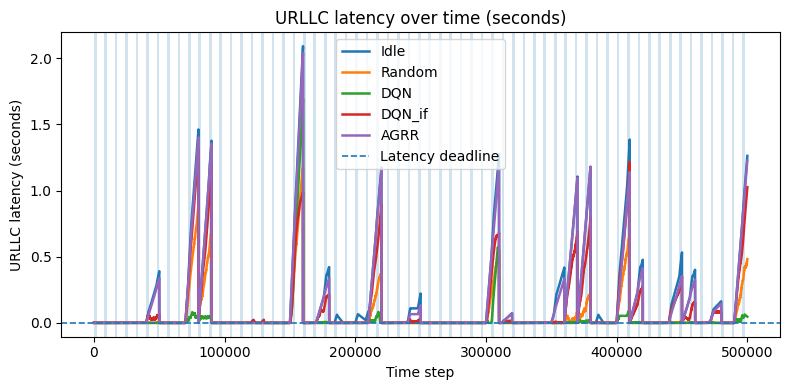

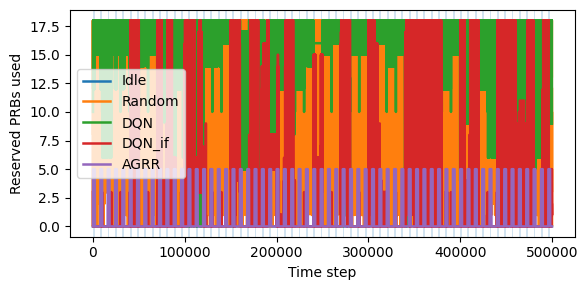

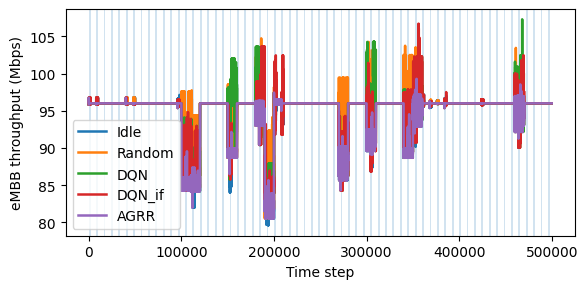

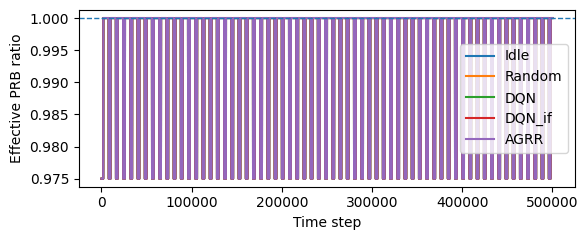


PLOTS FOR MILLISECONDS


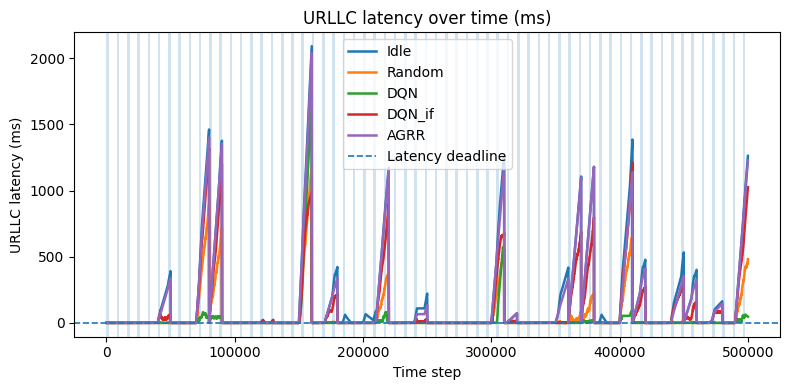

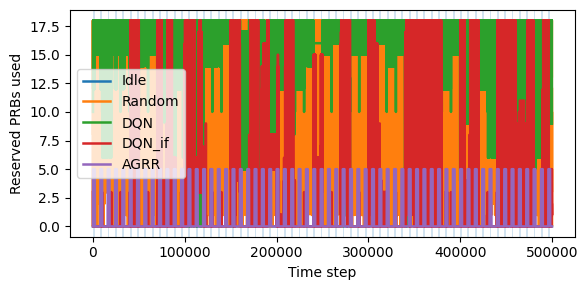

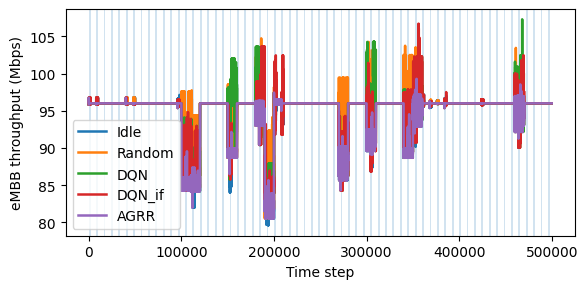

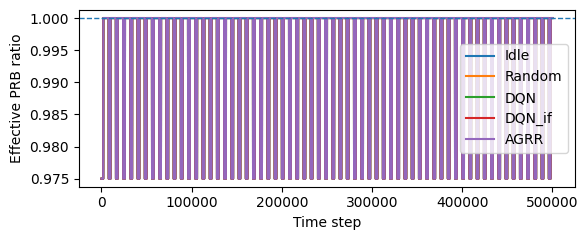

In [15]:
print("\n" + "="*100)
print("PLOTS FOR SECONDS")
print("="*100)
plot_urllc_latency(EVENTS, unit="sec")
plot_reserve_prb(EVENTS)
plot_embb_throughput(EVENTS)
plot_effective_prb(EVENTS)

print("\n" + "="*100)
print("PLOTS FOR MILLISECONDS")
print("="*100)
plot_urllc_latency(EVENTS, unit="ms")
plot_reserve_prb(EVENTS)
plot_embb_throughput(EVENTS)
plot_effective_prb(EVENTS)


### New Plot

In [3]:
from pathlib import Path
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.python.lib.io import tf_record
from tensorboard.compat.proto.event_pb2 import Event


# ----------------------------
# Config (EDIT THIS)
# ----------------------------
ROOT = Path("../../tb_logs/res_validator")  # <-- change this
POLICIES = ["aggressive", "idle", "dqn", "random","qrdqn"]
POWERS = [5, 10, 15, 20]

# Jam detection
JAM_THRESHOLD = 0.999   # you can tune; 0.995 or 0.99 might be better depending on your metric
TOLERANCE_STEPS = 5     # merge_asof tolerance


# ----------------------------
# Helpers
# ----------------------------
def read_scalar_from_event(event_file: Path, tag: str) -> pd.DataFrame:
    """Return DataFrame(step, value) for a scalar tag from a tfevents file."""
    rows = []
    for raw in tf_record.tf_record_iterator(str(event_file)):
        ev = Event.FromString(raw)
        if not ev.summary:
            continue
        step = int(ev.step)
        for v in ev.summary.value:
            if v.tag == tag and v.HasField("simple_value"):
                rows.append({"step": step, "value": float(v.simple_value)})
    if not rows:
        return pd.DataFrame(columns=["step", "value"])
    return pd.DataFrame(rows).sort_values("step").reset_index(drop=True)


def find_event_file(policy_dir: Path, test_dir_name: str) -> Path | None:
    """
    policy_dir/
      test_dir_name/
        run_dir/
          events.out.tfevents....
    Returns first (largest) event file found.
    """
    test_dir = policy_dir / test_dir_name
    if not test_dir.exists():
        return None

    run_dirs = [p for p in test_dir.iterdir() if p.is_dir()]
    if not run_dirs:
        return None

    # In your structure there is typically 1 run folder
    # but we search them all to be safe.
    candidates = []
    for rd in run_dirs:
        candidates.extend(list(rd.glob("events.out.tfevents.*")))

    if not candidates:
        return None

    # pick the biggest file (usually the full one)
    candidates.sort(key=lambda p: p.stat().st_size, reverse=True)
    return candidates[0]


def merge_latency_prb(lat_df: pd.DataFrame, prb_df: pd.DataFrame) -> pd.DataFrame:
    """Align latency and effective_ratio by nearest step."""
    lat_df = lat_df.rename(columns={"value": "latency_sec"}).sort_values("step")
    prb_df = prb_df.rename(columns={"value": "effective_prb_ratio"}).sort_values("step")

    df = pd.merge_asof(
        lat_df, prb_df,
        on="step",
        direction="nearest",
        tolerance=TOLERANCE_STEPS
    ).dropna().reset_index(drop=True)

    df["latency_ms"] = df["latency_sec"] * 1000.0  # seconds -> ms (correct if latency is in seconds)
    df["jammed"] = df["effective_prb_ratio"] < JAM_THRESHOLD
    return df


def mean_latency_during_jam(event_file: Path) -> float:
    """Compute mean URLLC latency (ms) during jammed samples."""
    lat = read_scalar_from_event(event_file, "latency/urllc")
    prb = read_scalar_from_event(event_file, "prb/effective_ratio")
    if lat.empty or prb.empty:
        return np.nan

    df = merge_latency_prb(lat, prb)
    jam_df = df[df["jammed"]]
    if jam_df.empty:
        return np.nan
    print("lent(jam(file)):", len(jam_df) )
    return float(jam_df["latency_ms"].mean())



def mean_latency_overall(event_file: Path) -> float:
    """Mean URLLC latency (ms) across all samples (jam + no-jam)."""
    lat = read_scalar_from_event(event_file, "latency/urllc")
    prb = read_scalar_from_event(event_file, "prb/effective_ratio")
    if lat.empty or prb.empty:
        return np.nan
    df = merge_latency_prb(lat, prb)
    if df.empty:
        return np.nan
    return float(df["latency_ms"].mean())


def mean_latency_no_jam(event_file: Path) -> float:
    """Mean URLLC latency (ms) during non-jammed samples only."""
    lat = read_scalar_from_event(event_file, "latency/urllc")
    prb = read_scalar_from_event(event_file, "prb/effective_ratio")
    if lat.empty or prb.empty:
        return np.nan
    df = merge_latency_prb(lat, prb)
    nojam_df = df[~df["jammed"]]
    if nojam_df.empty:
        return np.nan
    return float(nojam_df["latency_ms"].mean())



In [4]:
rows = []
for policy in POLICIES:
    policy_dir = ROOT / policy
    for pwr in POWERS:
        test_name = f"gym_from_testing_config_1ms_10s_8UE_jam_fixed_{pwr}"
        ev_file = find_event_file(policy_dir, test_name)

        if ev_file is None:
            rows.append({
                "policy": policy,
                "jam_prb": pwr,
                "lat_mean_all_ms": np.nan,
                "lat_mean_jam_ms": np.nan,
                "lat_mean_nojam_ms": np.nan,
                "event_file": None
            })
            continue

        rows.append({
            "policy": policy,
            "jam_prb": pwr,
            "lat_mean_all_ms": mean_latency_overall(ev_file),
            "lat_mean_jam_ms": mean_latency_during_jam(ev_file),
            "lat_mean_nojam_ms": mean_latency_no_jam(ev_file),
            "event_file": str(ev_file)
        })

df = pd.DataFrame(rows)
df


lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950


,policy,jam_prb,lat_mean_all_ms,lat_mean_jam_ms,lat_mean_nojam_ms,event_file
0,aggressive,5,146.943985,129.402536,164.450352,../../tb_logs/res_validator/aggressive/gym_fro...
1,aggressive,10,147.121448,129.595947,164.611899,../../tb_logs/res_validator/aggressive/gym_fro...
2,aggressive,15,147.527818,130.083542,164.937206,../../tb_logs/res_validator/aggressive/gym_fro...
3,aggressive,20,147.855425,130.489663,165.186456,../../tb_logs/res_validator/aggressive/gym_fro...
4,idle,5,173.860991,153.594184,194.087264,../../tb_logs/res_validator/idle/gym_from_test...
5,idle,10,208.978170,184.764616,233.143298,../../tb_logs/res_validator/idle/gym_from_test...
6,idle,15,268.155309,237.162044,299.086587,../../tb_logs/res_validator/idle/gym_from_test...
7,idle,20,301.169009,266.954424,335.315164,../../tb_logs/res_validator/idle/gym_from_test...
8,dqn,5,101.057005,89.988186,112.103687,../../tb_logs/res_validator/dqn/gym_from_testi...
9,dqn,10,93.498812,83.532680,103.445012,../../tb_logs/res_validator/dqn/gym_from_testi...


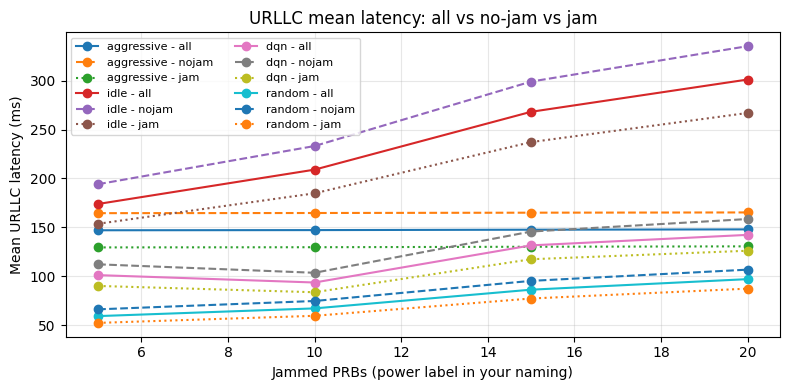

In [47]:
plt.figure(figsize=(8, 4))

for policy in POLICIES:
    sub = df[df.policy == policy].sort_values("jam_prb")
    plt.plot(sub["jam_prb"], sub["lat_mean_all_ms"], marker="o", label=f"{policy} - all")
    plt.plot(sub["jam_prb"], sub["lat_mean_nojam_ms"], marker="o", linestyle="--", label=f"{policy} - nojam")
    plt.plot(sub["jam_prb"], sub["lat_mean_jam_ms"], marker="o", linestyle=":", label=f"{policy} - jam")

plt.xlabel("Jammed PRBs (power label in your naming)")
plt.ylabel("Mean URLLC latency (ms)")
plt.title("URLLC mean latency: all vs no-jam vs jam")
plt.grid(True, alpha=0.3)
plt.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()


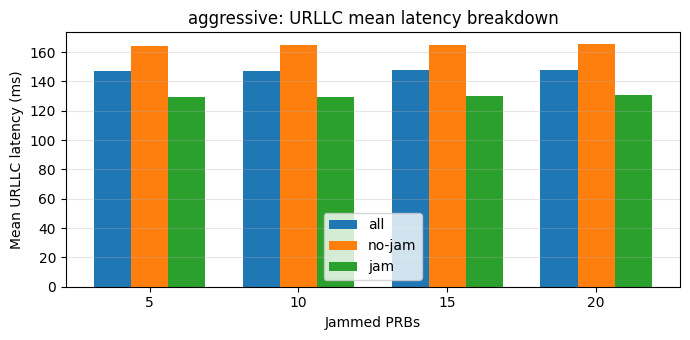

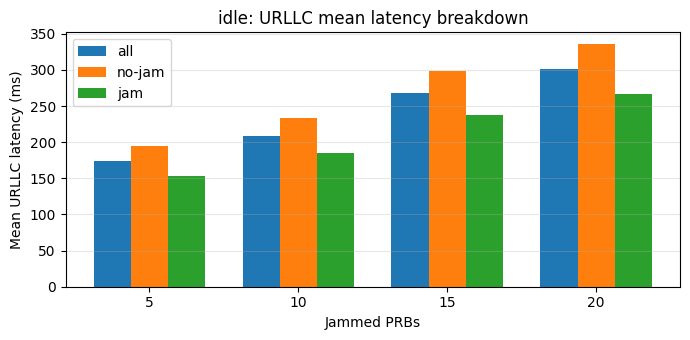

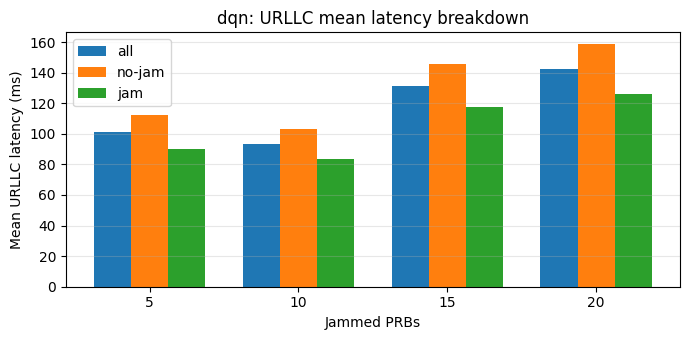

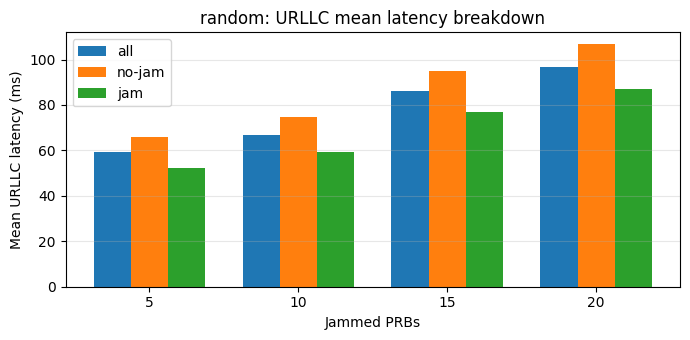

In [48]:
import numpy as np

for policy in POLICIES:
    sub = df[df.policy == policy].sort_values("jam_prb")
    x = np.arange(len(sub))
    w = 0.25

    plt.figure(figsize=(7, 3.5))
    plt.bar(x - w, sub["lat_mean_all_ms"], width=w, label="all")
    plt.bar(x,      sub["lat_mean_nojam_ms"], width=w, label="no-jam")
    plt.bar(x + w,  sub["lat_mean_jam_ms"], width=w, label="jam")

    plt.xticks(x, sub["jam_prb"])
    plt.xlabel("Jammed PRBs")
    plt.ylabel("Mean URLLC latency (ms)")
    plt.title(f"{policy}: URLLC mean latency breakdown")
    plt.grid(True, axis="y", alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()


In [5]:
# ----------------------------
# Collect data
# ----------------------------
rows = []
for policy in POLICIES:
    policy_dir = ROOT / policy
    for pwr in POWERS:
        test_name = f"gym_from_testing_config_1ms_10s_8UE_jam_fixed_{pwr}"
        ev_file = find_event_file(policy_dir, test_name)
        if ev_file is None:
            rows.append({"policy": policy, "jam_prb": pwr, "mean_latency_ms": np.nan, "event_file": None})
            continue

        m = mean_latency_during_jam(ev_file)
        rows.append({"policy": policy, "jam_prb": pwr, "mean_latency_ms": m, "event_file": str(ev_file)})

df = pd.DataFrame(rows)
df


lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950


,policy,jam_prb,mean_latency_ms,event_file
0,aggressive,5,129.402536,../../tb_logs/res_validator/aggressive/gym_fro...
1,aggressive,10,129.595947,../../tb_logs/res_validator/aggressive/gym_fro...
2,aggressive,15,130.083542,../../tb_logs/res_validator/aggressive/gym_fro...
3,aggressive,20,130.489663,../../tb_logs/res_validator/aggressive/gym_fro...
4,idle,5,153.594184,../../tb_logs/res_validator/idle/gym_from_test...
5,idle,10,184.764616,../../tb_logs/res_validator/idle/gym_from_test...
6,idle,15,237.162044,../../tb_logs/res_validator/idle/gym_from_test...
7,idle,20,266.954424,../../tb_logs/res_validator/idle/gym_from_test...
8,dqn,5,89.988186,../../tb_logs/res_validator/dqn/gym_from_testi...
9,dqn,10,83.532680,../../tb_logs/res_validator/dqn/gym_from_testi...


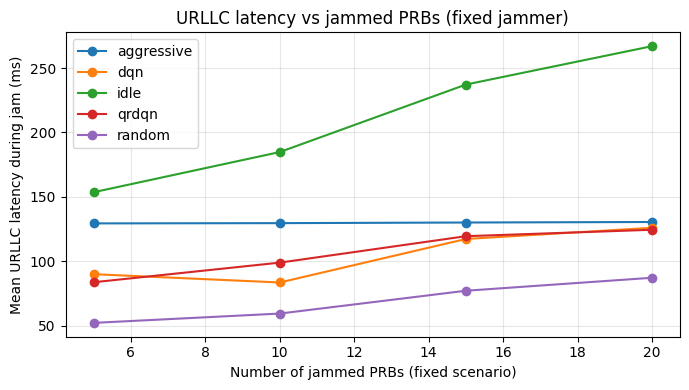

In [6]:
plt.figure(figsize=(7, 4))

for policy, g in df.groupby("policy"):
    g = g.sort_values("jam_prb")
    plt.plot(g["jam_prb"], g["mean_latency_ms"], marker="o", label=policy)

plt.xlabel("Number of jammed PRBs (fixed scenario)")
plt.ylabel("Mean URLLC latency during jam (ms)")
plt.title("URLLC latency vs jammed PRBs (fixed jammer)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [7]:
def merge_throughput_prb(thr_df: pd.DataFrame, prb_df: pd.DataFrame) -> pd.DataFrame:
    """Align eMBB throughput and effective_ratio by nearest step."""
    thr_df = thr_df.rename(columns={"value": "embb_mbps"}).sort_values("step")
    prb_df = prb_df.rename(columns={"value": "effective_prb_ratio"}).sort_values("step")

    df = pd.merge_asof(
        thr_df, prb_df,
        on="step",
        direction="nearest",
        tolerance=TOLERANCE_STEPS
    ).dropna().reset_index(drop=True)

    df["jammed"] = df["effective_prb_ratio"] < JAM_THRESHOLD
    return df


def mean_embb_throughput_during_jam(event_file: Path) -> float:
    """Compute mean eMBB throughput (Mbps) during jammed samples."""
    thr = read_scalar_from_event(event_file, "throughput/embb_mbps")
    prb = read_scalar_from_event(event_file, "prb/effective_ratio")
    if thr.empty or prb.empty:
        return np.nan

    df = merge_throughput_prb(thr, prb)
    jam_df = df[df["jammed"]]
    if jam_df.empty:
        return np.nan
    return float(jam_df["embb_mbps"].mean())

rows_thr = []
for policy in POLICIES:
    policy_dir = ROOT / policy
    for pwr in POWERS:
        test_name = f"gym_from_testing_config_1ms_10s_8UE_jam_fixed_{pwr}"
        ev_file = find_event_file(policy_dir, test_name)
        if ev_file is None:
            rows_thr.append({"policy": policy, "jam_prb": pwr, "mean_embb_mbps": np.nan, "event_file": None})
            continue

        m = mean_embb_throughput_during_jam(ev_file)
        rows_thr.append({"policy": policy, "jam_prb": pwr, "mean_embb_mbps": m, "event_file": str(ev_file)})

df_thr = pd.DataFrame(rows_thr)
df_thr


,policy,jam_prb,mean_embb_mbps,event_file
0,aggressive,5,94.818603,../../tb_logs/res_validator/aggressive/gym_fro...
1,aggressive,10,94.802386,../../tb_logs/res_validator/aggressive/gym_fro...
2,aggressive,15,94.786921,../../tb_logs/res_validator/aggressive/gym_fro...
3,aggressive,20,94.534907,../../tb_logs/res_validator/aggressive/gym_fro...
4,idle,5,94.280645,../../tb_logs/res_validator/idle/gym_from_test...
5,idle,10,93.284532,../../tb_logs/res_validator/idle/gym_from_test...
6,idle,15,92.315348,../../tb_logs/res_validator/idle/gym_from_test...
7,idle,20,90.594324,../../tb_logs/res_validator/idle/gym_from_test...
8,dqn,5,95.032429,../../tb_logs/res_validator/dqn/gym_from_testi...
9,dqn,10,94.454199,../../tb_logs/res_validator/dqn/gym_from_testi...


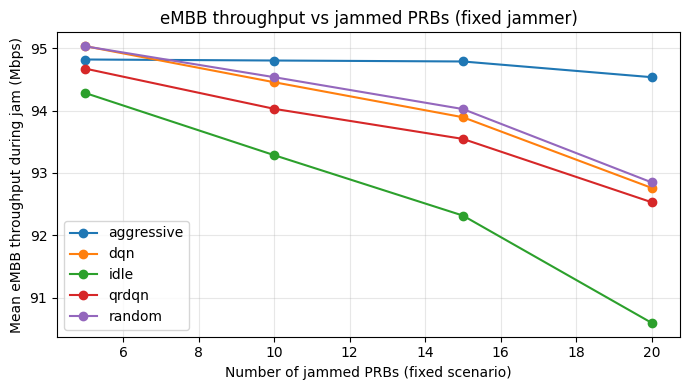

In [8]:
plt.figure(figsize=(7, 4))

for policy, g in df_thr.groupby("policy"):
    g = g.sort_values("jam_prb")
    plt.plot(g["jam_prb"], g["mean_embb_mbps"], marker="o", label=policy)

plt.xlabel("Number of jammed PRBs (fixed scenario)")
plt.ylabel("Mean eMBB throughput during jam (Mbps)")
plt.title("eMBB throughput vs jammed PRBs (fixed jammer)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [9]:
def mean_reserve_used_prb_during_jam(event_file: Path) -> float:
    """
    Mean reserve used PRBs (obs/reserve_used_prb) during jammed samples.
    """
    rsv = read_scalar_from_event(event_file, "obs/reserve_used_prb")
    prb = read_scalar_from_event(event_file, "prb/effective_ratio")
    if rsv.empty or prb.empty:
        return np.nan

    rsv = rsv.rename(columns={"value": "reserve_used_prb"}).sort_values("step")
    prb = prb.rename(columns={"value": "effective_prb_ratio"}).sort_values("step")

    df = pd.merge_asof(
        rsv, prb,
        on="step",
        direction="nearest",
        tolerance=TOLERANCE_STEPS
    ).dropna().reset_index(drop=True)

    df["jammed"] = df["effective_prb_ratio"] < JAM_THRESHOLD
    jam_df = df[df["jammed"]]
    if jam_df.empty:
        return np.nan
    return float(jam_df["reserve_used_prb"].mean())


rows_prb = []
for policy in POLICIES:
    policy_dir = ROOT / policy
    for pwr in POWERS:
        test_name = f"gym_from_testing_config_1ms_10s_8UE_jam_fixed_{pwr}"
        ev_file = find_event_file(policy_dir, test_name)
        if ev_file is None:
            rows_prb.append({"policy": policy, "jam_prb": pwr, "reserve_used_prb_mean": np.nan})
            continue
        m = mean_reserve_used_prb_during_jam(ev_file)
        rows_prb.append({"policy": policy, "jam_prb": pwr, "reserve_used_prb_mean": m})

df_prb = pd.DataFrame(rows_prb)
df_prb


,policy,jam_prb,reserve_used_prb_mean
0,aggressive,5,4.951904
1,aggressive,10,9.935872
2,aggressive,15,14.847695
3,aggressive,20,17.791583
4,idle,5,0.000000
5,idle,10,0.000000
6,idle,15,0.000000
7,idle,20,0.000000
8,dqn,5,5.204569
9,dqn,10,6.218998


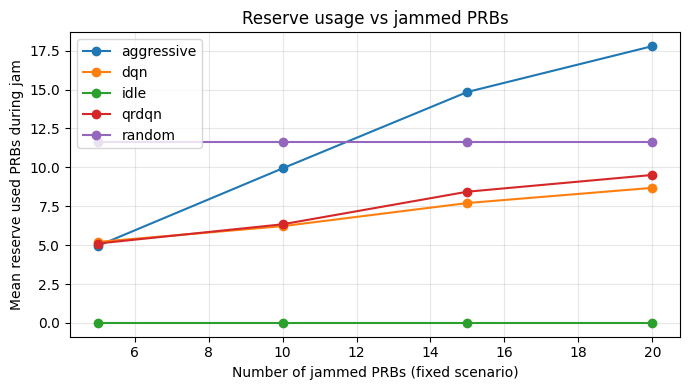

In [10]:
plt.figure(figsize=(7,4))
for policy, g in df_prb.groupby("policy"):
    g = g.sort_values("jam_prb")
    plt.plot(g["jam_prb"], g["reserve_used_prb_mean"], marker="o", label=policy)

plt.xlabel("Number of jammed PRBs (fixed scenario)")
plt.ylabel("Mean reserve used PRBs during jam")
plt.title("Reserve usage vs jammed PRBs")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [11]:
from pathlib import Path
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.python.lib.io import tf_record
from tensorboard.compat.proto.event_pb2 import Event

# -------- EDIT THIS --------
ROOT = Path("../../tb_logs/res_validator")  # <-- change
POLICIES = ["aggressive", "idle", "dqn", "random","qrdqn"]
PATTERNS = ["fixed", "increasing", "decreasing", "random"]

# Jam detection threshold (tune if needed)
JAM_THRESHOLD = 0.999
TOLERANCE_STEPS = 5

# Timing (you said 1 ms per sim step)
STEP_MS = 1

JAM_MS = 1250     # jam duration = 1250 ms
PRE_MS = 200
POST_MS = 2000
DEADLINE_MS = 1.0

# convert ms -> steps used in event.step
JAM_STEPS  = int(JAM_MS / STEP_MS)
PRE_STEPS  = int(PRE_MS / STEP_MS)
POST_STEPS = int(POST_MS / STEP_MS)


In [12]:
def read_scalar_from_event(event_file: Path, tag: str) -> pd.DataFrame:
    rows = []
    for raw in tf_record.tf_record_iterator(str(event_file)):
        ev = Event.FromString(raw)
        if not ev.summary:
            continue
        step = int(ev.step)
        for v in ev.summary.value:
            if v.tag == tag and v.HasField("simple_value"):
                rows.append({"step": step, "value": float(v.simple_value)})
    if not rows:
        return pd.DataFrame(columns=["step", "value"])
    return pd.DataFrame(rows).sort_values("step").reset_index(drop=True)


def find_event_file(policy_dir: Path, test_dir_name: str) -> Path | None:
    test_dir = policy_dir / test_dir_name
    if not test_dir.exists():
        return None
    run_dirs = [p for p in test_dir.iterdir() if p.is_dir()]
    if not run_dirs:
        return None
    candidates = []
    for rd in run_dirs:
        candidates.extend(list(rd.glob("events.out.tfevents.*")))
    if not candidates:
        return None
    candidates.sort(key=lambda p: p.stat().st_size, reverse=True)
    return candidates[0]


def merge_asof_by_step(df_a: pd.DataFrame, df_b: pd.DataFrame, tol=TOLERANCE_STEPS):
    return (
        pd.merge_asof(
            df_a.sort_values("step"),
            df_b.sort_values("step"),
            on="step",
            direction="nearest",
            tolerance=tol
        ).dropna().reset_index(drop=True)
    )


def detect_jam_starts(df, jam_threshold=JAM_THRESHOLD, cooldown_steps=JAM_STEPS):
    jammed = df["effective_prb_ratio"] < jam_threshold
    starts = np.where(jammed & (~jammed.shift(1).fillna(False)))[0]
    # cooldown to avoid repeated triggers during same burst
    kept = []
    last = -10**12
    for s in starts:
        if s - last >= cooldown_steps:
            kept.append(s)
            last = s
    return kept


def event_aligned_mean(df, value_col, start_rows, pre_steps=PRE_STEPS, post_steps=POST_STEPS):
    aligned = []
    for r in start_rows:
        s = r - pre_steps
        e = r + post_steps
        if s < 0 or e > len(df):
            continue
        w = df.iloc[s:e].copy()
        w["t_rel"] = np.arange(-pre_steps, post_steps)  # in "steps"
        aligned.append(w[["t_rel", value_col]])
    if not aligned:
        return pd.DataFrame(columns=["t_rel", "mean", "std"])
    A = pd.concat(aligned, ignore_index=True)
    g = A.groupby("t_rel")[value_col]
    return pd.DataFrame({"t_rel": g.mean().index, "mean": g.mean().values, "std": g.std().values})


In [13]:
def load_and_align_one_run(event_file: Path):
    # Read required tags
    lat = read_scalar_from_event(event_file, "latency/urllc").rename(columns={"value": "latency_sec"})
    thr = read_scalar_from_event(event_file, "throughput/embb_mbps").rename(columns={"value": "embb_mbps"})
    prb = read_scalar_from_event(event_file, "prb/effective_ratio").rename(columns={"value": "effective_prb_ratio"})
    rsv = read_scalar_from_event(event_file, "obs/reserve_used_prb").rename(columns={"value": "reserve_used_prb"})

    if lat.empty or thr.empty or prb.empty:
        return None  # insufficient

    # Merge to common steps (start from prb, then join others)
    df = prb.copy()
    df = merge_asof_by_step(df, lat)
    df = merge_asof_by_step(df, thr)

    if not rsv.empty:
        df = merge_asof_by_step(df, rsv)
    else:
        df["reserve_used_prb"] = np.nan

    # Convert latency to ms
    df["latency_ms"] = df["latency_sec"] * 1000.0
    return df


aligned_lat = {}   # (pattern, policy) -> df(t_rel, mean, std)
aligned_thr = {}   # (pattern, policy) -> df(t_rel, mean, std)
aligned_eff = {}   # (pattern, policy) -> df(t_rel, mean, std)

summary_rows = []

for policy in POLICIES:
    policy_dir = ROOT / policy
    for pat in PATTERNS:
        test_name = f"gym_from_testing_config_1ms_10s_8UE_jam_pattern_{pat}"
        ev = find_event_file(policy_dir, test_name)
        if ev is None:
            summary_rows.append({"policy": policy, "pattern": pat, "n_jam_events": 0,
                                 "violation_pct": np.nan, "jam_thr_mbps": np.nan, "jam_reserve_used": np.nan})
            continue

        df = load_and_align_one_run(ev)
        if df is None:
            summary_rows.append({"policy": policy, "pattern": pat, "n_jam_events": 0,
                                 "violation_pct": np.nan, "jam_thr_mbps": np.nan, "jam_reserve_used": np.nan})
            continue

        starts = detect_jam_starts(df)

        # Aligned curves
        lat_al = event_aligned_mean(df, "latency_ms", starts)
        thr_al = event_aligned_mean(df, "embb_mbps", starts)
        eff_al = event_aligned_mean(df, "effective_prb_ratio", starts)

        aligned_lat[(pat, policy)] = lat_al
        aligned_thr[(pat, policy)] = thr_al
        aligned_eff[(pat, policy)] = eff_al

        # Summary metrics during jam window [0, JAM_STEPS)
        if not lat_al.empty:
            jam_lat = lat_al[(lat_al.t_rel >= 0) & (lat_al.t_rel < JAM_STEPS)]["mean"].to_numpy()
            violation_pct = float(np.mean(jam_lat > DEADLINE_MS) * 100.0) if len(jam_lat) else np.nan
        else:
            violation_pct = np.nan

        if not thr_al.empty:
            jam_thr = thr_al[(thr_al.t_rel >= 0) & (thr_al.t_rel < JAM_STEPS)]["mean"].mean()
            jam_thr = float(jam_thr) if np.isfinite(jam_thr) else np.nan
        else:
            jam_thr = np.nan

        # reserve usage: compute directly from raw df during jammed samples
        df["jammed"] = df["effective_prb_ratio"] < JAM_THRESHOLD
        jam_df = df[df["jammed"]]
        jam_reserve_used = float(jam_df["reserve_used_prb"].mean()) if (not jam_df.empty) else np.nan

        summary_rows.append({
            "policy": policy,
            "pattern": pat,
            "n_jam_events": len(starts),
            "violation_pct": violation_pct,
            "jam_thr_mbps": jam_thr,
            "jam_reserve_used": jam_reserve_used,
            "event_file": str(ev),
        })

summary_df = pd.DataFrame(summary_rows)
summary_df


/tmp/ipykernel_966323/2704837859.py:46: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  starts = np.where(jammed & (~jammed.shift(1).fillna(False)))[0]
/tmp/ipykernel_966323/2704837859.py:46: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  starts = np.where(jammed & (~jammed.shift(1).fillna(False)))[0]
/tmp/ipykernel_966323/2704837859.py:46: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_op

,policy,pattern,n_jam_events,violation_pct,jam_thr_mbps,jam_reserve_used,event_file
0,aggressive,fixed,34,100.0,94.646265,4.951904,../../tb_logs/res_validator/aggressive/gym_fro...
1,aggressive,increasing,34,100.0,94.613763,11.885772,../../tb_logs/res_validator/aggressive/gym_fro...
2,aggressive,decreasing,34,100.0,94.613290,11.869739,../../tb_logs/res_validator/aggressive/gym_fro...
3,aggressive,random,34,100.0,94.606603,12.211062,../../tb_logs/res_validator/aggressive/gym_fro...
4,idle,fixed,34,100.0,94.386035,0.000000,../../tb_logs/res_validator/idle/gym_from_test...
5,idle,increasing,34,100.0,93.869297,0.000000,../../tb_logs/res_validator/idle/gym_from_test...
6,idle,decreasing,34,100.0,93.890808,0.000000,../../tb_logs/res_validator/idle/gym_from_test...
7,idle,random,34,100.0,93.751206,0.000000,../../tb_logs/res_validator/idle/gym_from_test...
8,dqn,fixed,34,100.0,95.150805,5.204569,../../tb_logs/res_validator/dqn/gym_from_testi...
9,dqn,increasing,34,100.0,94.680644,7.111703,../../tb_logs/res_validator/dqn/gym_from_testi...


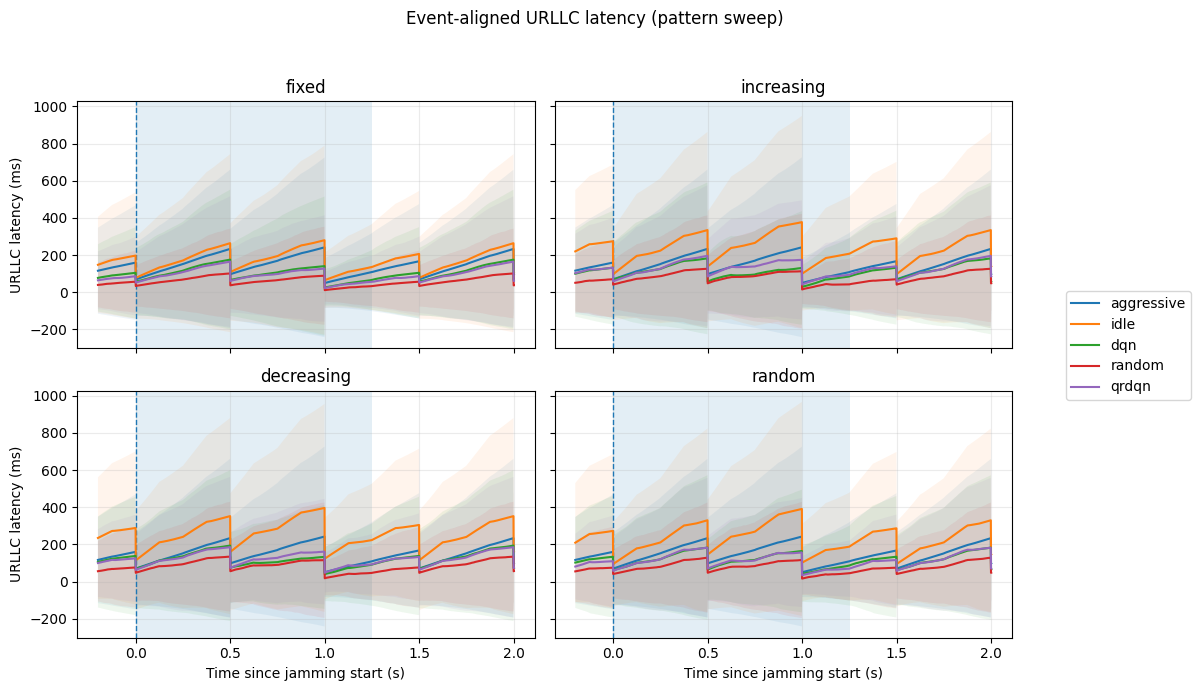

In [14]:
def plot_aligned_grid(aligned_dict, title, ylabel, jam_ms=JAM_MS):
    fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)
    axes = axes.flatten()

    for i, pat in enumerate(PATTERNS):
        ax = axes[i]
        ax.axvspan(0, jam_ms/1000.0, alpha=0.12)   # jam ON
        ax.axvline(0, linestyle="--", linewidth=1)
        ax.set_title(pat)

        for pol in POLICIES:
            df = aligned_dict.get((pat, pol))
            if df is None or df.empty:
                continue
            t_sec = (df["t_rel"].to_numpy() * STEP_MS) / 1000.0
            m = df["mean"].to_numpy()
            s = df["std"].to_numpy()
            ax.plot(t_sec, m, label=pol)
            if np.isfinite(s).any():
                ax.fill_between(t_sec, m - s, m + s, alpha=0.08)

        ax.grid(True, alpha=0.25)

    for ax in axes[2:]:
        ax.set_xlabel("Time since jamming start (s)")
    for ax in axes[0::2]:
        ax.set_ylabel(ylabel)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="center right", frameon=True)
    fig.suptitle(title)
    fig.tight_layout(rect=[0, 0, 0.86, 0.95])
    plt.show()


plot_aligned_grid(
    aligned_lat,
    title="Event-aligned URLLC latency (pattern sweep)",
    ylabel="URLLC latency (ms)"
)


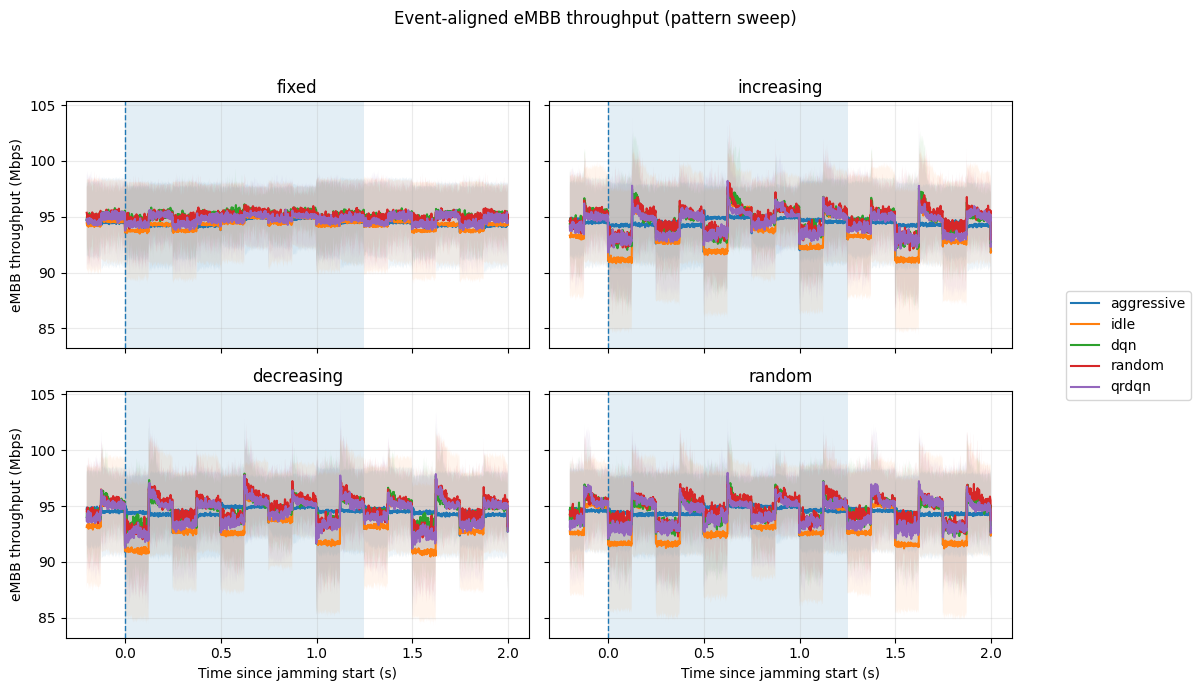

In [15]:
plot_aligned_grid(
    aligned_thr,
    title="Event-aligned eMBB throughput (pattern sweep)",
    ylabel="eMBB throughput (Mbps)"
)


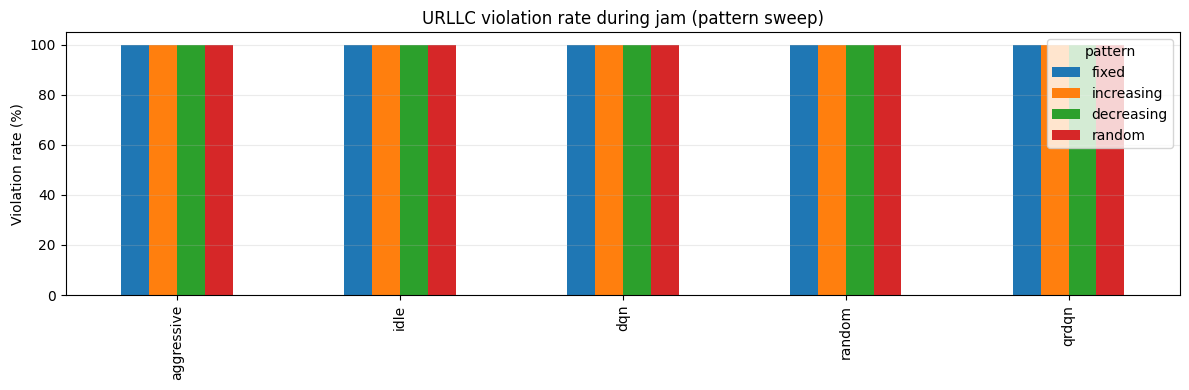

In [16]:
pivot_v = summary_df.pivot_table(index="policy", columns="pattern", values="violation_pct", aggfunc="mean")
pivot_v = pivot_v.reindex(index=POLICIES, columns=PATTERNS)

ax = pivot_v.plot(kind="bar", figsize=(12,4))
ax.set_title("URLLC violation rate during jam (pattern sweep)")
ax.set_ylabel("Violation rate (%)")
ax.set_xlabel("")
ax.grid(True, axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


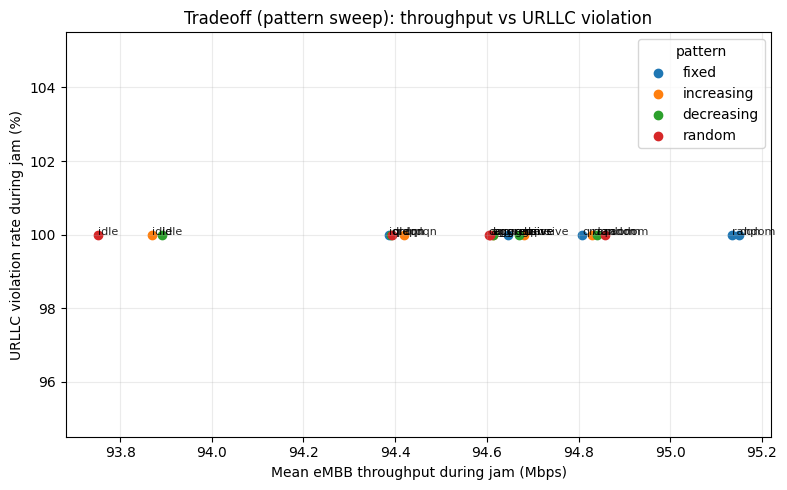

In [17]:
plt.figure(figsize=(8,5))
for pat in PATTERNS:
    g = summary_df[summary_df["pattern"] == pat]
    plt.scatter(g["jam_thr_mbps"], g["violation_pct"], label=pat)
    for _, r in g.iterrows():
        if np.isfinite(r["jam_thr_mbps"]) and np.isfinite(r["violation_pct"]):
            plt.annotate(r["policy"], (r["jam_thr_mbps"], r["violation_pct"]), fontsize=8, alpha=0.85)

plt.xlabel("Mean eMBB throughput during jam (Mbps)")
plt.ylabel("URLLC violation rate during jam (%)")
plt.title("Tradeoff (pattern sweep): throughput vs URLLC violation")
plt.grid(True, alpha=0.25)
plt.legend(title="pattern")
plt.tight_layout()
plt.show()


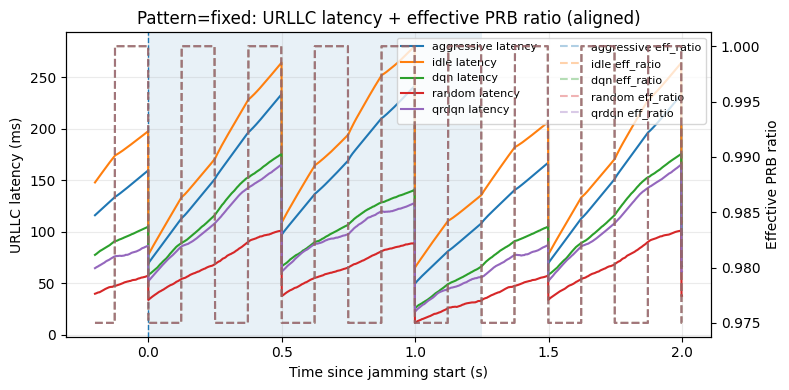

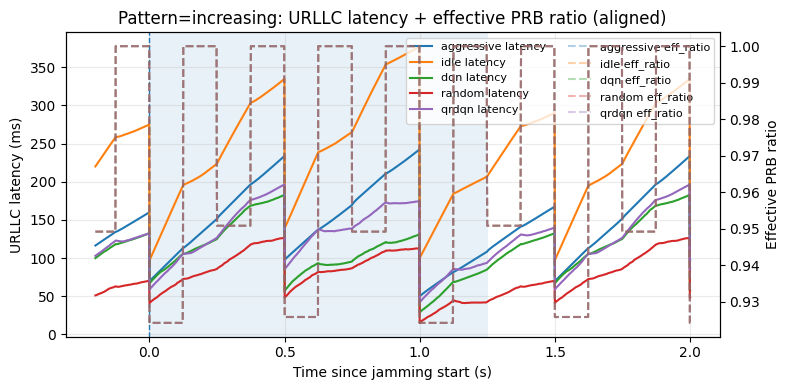

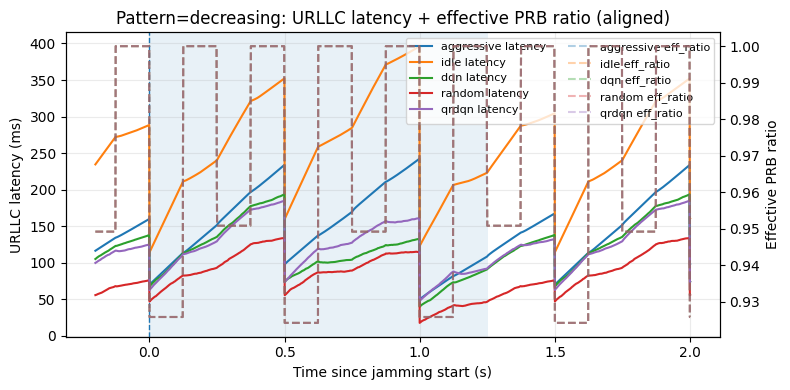

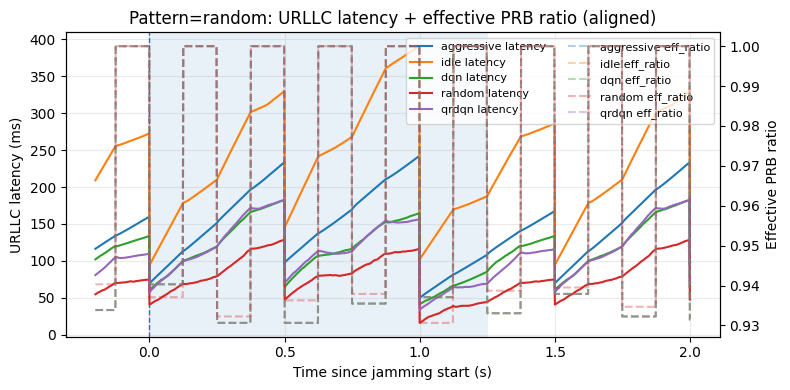

In [18]:
def plot_latency_with_effective_ratio(pattern, policies=POLICIES):
    fig, ax1 = plt.subplots(figsize=(8,4))
    ax2 = ax1.twinx()

    # Jam shading (in seconds)
    ax1.axvspan(0, JAM_MS/1000.0, alpha=0.10)
    ax1.axvline(0, linestyle="--", linewidth=1)

    for pol in policies:
        lat = aligned_lat.get((pattern, pol))
        eff = aligned_eff.get((pattern, pol))
        if lat is None or lat.empty or eff is None or eff.empty:
            continue

        t_sec = (lat["t_rel"].to_numpy() * STEP_MS) / 1000.0
        ax1.plot(t_sec, lat["mean"].to_numpy(), label=f"{pol} latency")

        # effective ratio (faint)
        ax2.plot(t_sec, eff["mean"].to_numpy(), linestyle="--", alpha=0.35, label=f"{pol} eff_ratio")

    ax1.set_title(f"Pattern={pattern}: URLLC latency + effective PRB ratio (aligned)")
    ax1.set_xlabel("Time since jamming start (s)")
    ax1.set_ylabel("URLLC latency (ms)")
    ax2.set_ylabel("Effective PRB ratio")

    ax1.grid(True, alpha=0.25)

    # combined legend
    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, fontsize=8, ncol=2, frameon=True, loc="upper right")

    plt.tight_layout()
    plt.show()


# Run one pattern at a time (recommended)
plot_latency_with_effective_ratio("fixed")
plot_latency_with_effective_ratio("increasing")
plot_latency_with_effective_ratio("decreasing")
plot_latency_with_effective_ratio("random")


In [19]:
def recovery_time_deadline(lat_al: pd.DataFrame,
                           jam_ms=1250,
                           deadline_ms=1.0,
                           hold_ms=50):
    """
    lat_al: DataFrame with columns ['t_rel','mean'] where t_rel is ms relative to jam start.
    Returns recovery time in ms AFTER jam end (t=jam_ms).
    """
    if lat_al is None or lat_al.empty:
        return np.nan

    post = lat_al[lat_al["t_rel"] >= jam_ms].copy().reset_index(drop=True)
    if post.empty:
        return np.nan

    ok = (post["mean"].to_numpy() <= deadline_ms).astype(int)
    H = int(hold_ms)

    if H <= 1:
        idx = np.where(ok == 1)[0]
        return float(post.loc[idx[0], "t_rel"] - jam_ms) if len(idx) else np.nan

    run = np.convolve(ok, np.ones(H, dtype=int), mode="valid")
    idx = np.where(run == H)[0]
    if len(idx) == 0:
        return np.nan

    t_first = float(post.loc[idx[0], "t_rel"])
    return t_first - jam_ms


In [20]:
def recovery_time_baseline(lat_al: pd.DataFrame,
                           jam_ms=1250,
                           pre_window_ms=200,
                           eps=0.10,
                           hold_ms=50):
    """
    Recovery when latency returns within (1+eps)*baseline for hold_ms.
    Baseline computed from [-pre_window_ms, 0).
    Returns recovery time in ms after jam end.
    """
    if lat_al is None or lat_al.empty:
        return np.nan

    pre = lat_al[(lat_al["t_rel"] >= -pre_window_ms) & (lat_al["t_rel"] < 0)]
    if pre.empty:
        return np.nan

    baseline = float(pre["mean"].mean())
    if not np.isfinite(baseline) or baseline <= 0:
        return np.nan

    thresh = baseline * (1.0 + eps)

    post = lat_al[lat_al["t_rel"] >= jam_ms].copy().reset_index(drop=True)
    if post.empty:
        return np.nan

    ok = (post["mean"].to_numpy() <= thresh).astype(int)
    H = int(hold_ms)

    run = np.convolve(ok, np.ones(H, dtype=int), mode="valid") if H > 1 else ok
    idx = np.where(run == H)[0] if H > 1 else np.where(run == 1)[0]
    if len(idx) == 0:
        return np.nan

    t_first = float(post.loc[idx[0], "t_rel"])
    return t_first - jam_ms


In [21]:
# lat_al is your aligned latency DataFrame for one policy+pattern (mean in ms)
rt_deadline = recovery_time_deadline(lat_al, jam_ms=1250, deadline_ms=1.0, hold_ms=50)
rt_base = recovery_time_baseline(lat_al, jam_ms=1250, pre_window_ms=200, eps=0.10, hold_ms=50)

print("Recovery (deadline):", rt_deadline, "ms after jam end")
print("Recovery (baseline):", rt_base, "ms after jam end")


Recovery (deadline): nan ms after jam end
Recovery (baseline): 0.0 ms after jam end



=== Summary ===
        policy     pattern  n_jam_events  tb_stride  jam_on_tb_steps  \
0   aggressive       fixed           200         10              125   
1   aggressive  increasing           200         10              125   
2   aggressive  decreasing           200         10              125   
3   aggressive      random           200         10              125   
4         idle       fixed           200         10              125   
5         idle  increasing           200         10              125   
6         idle  decreasing           200         10              125   
7         idle      random           200         10              125   
8          dqn       fixed           200         10              125   
9          dqn  increasing           200         10              125   
10         dqn  decreasing           200         10              125   
11         dqn      random           200         10              125   
12      random       fixed           200       

/tmp/ipykernel_966323/2378258628.py:352: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  lat_pivot = summary_df.pivot_table(index="policy", columns="pattern", values="jam_lat_ms", aggfunc="mean")


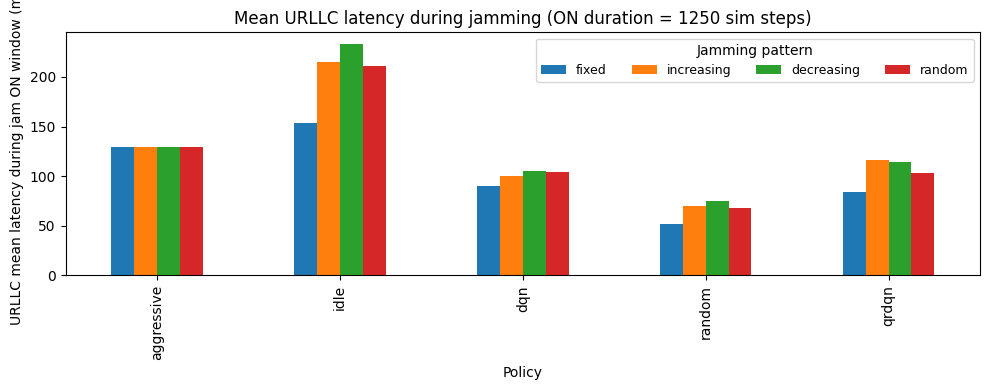

/tmp/ipykernel_966323/2378258628.py:362: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  thr_pivot = summary_df.pivot_table(index="policy", columns="pattern", values="jam_thr_mbps", aggfunc="mean")


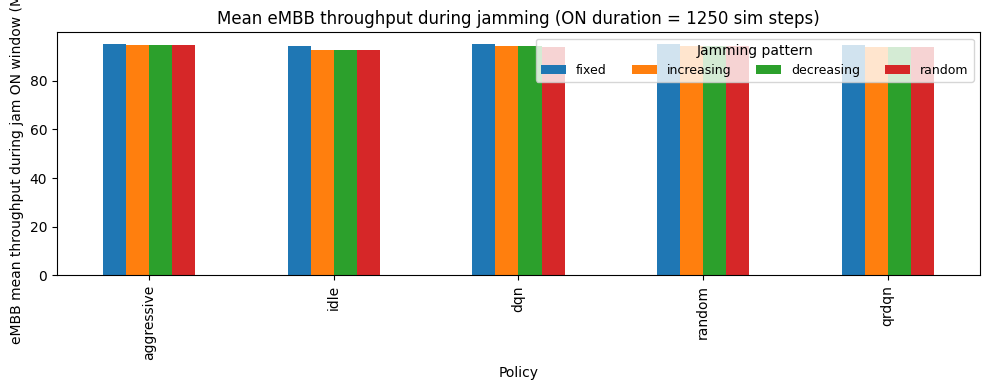


Saved summary CSV and plots to: /home/elahe/user/elahe/RL_work/Resilient_PRB_allocation/backend/tb_logs/res_validator/_plots


<Figure size 1000x400 with 0 Axes>

<Figure size 1000x400 with 0 Axes>

In [22]:
#!/usr/bin/env python3
"""
TensorBoard -> summary table + bar charts for URLLC latency and eMBB throughput
across policies and jamming patterns.

This version is FIXED for your periodic jammer:
- Jam ON duration = 1250 simulator steps
- Jam period      = 2500 simulator steps

It automatically:
1) Infers the TensorBoard step stride (e.g., 1 if logging every sim step, 10 if logging every decision step).
2) Converts (1250, 2500) sim-steps into TB-step units.
3) Detects jam starts with a minimum-gap ~= one period (to avoid multiple starts in one ON interval).
4) Aligns by ROW INDEX (robust even if TB steps jump by 10/100/etc.).
5) Avoids the "Mean of empty slice" warnings by guarding n==0.

Folder layout expected:
ROOT/
  aggressive/
  idle/
  dqn/
  random/
  qrdqn/
Each contains TB runs under subfolders, each containing events.out.tfevents.*.
"""

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing import event_accumulator


# -----------------------------
# User settings
# -----------------------------
ROOT = Path("../../tb_logs/res_validator")  # <-- change if needed

POLICIES = ["aggressive", "idle", "dqn", "random", "qrdqn"]
PATTERNS = ["fixed", "increasing", "decreasing", "random"]

# Jam detection threshold (effective PRB ratio lower than this => jammed)
JAM_THRESHOLD = 0.999

# URLLC deadline (ms) used for violation %
DEADLINE_MS = 1.0

# Your jammer (SIMULATOR steps)
JAM_ON_STEPS_SIM = 1250
JAM_PERIOD_STEPS_SIM = 2500

# Alignment window (in TB-step units after conversion)
PRE_STEPS = 0   # show from jam start
POST_EXTRA = 0  # extra beyond one period (set e.g. 200 if you want)


# -----------------------------
# TensorBoard helpers
# -----------------------------
def read_scalar_from_event(event_file: Path, tag: str) -> pd.DataFrame:
    """Returns DataFrame columns: step, wall_time, value (sorted by step)."""
    ea = event_accumulator.EventAccumulator(str(event_file), size_guidance={"scalars": 0})
    ea.Reload()
    tags = ea.Tags().get("scalars", [])
    if tag not in tags:
        return pd.DataFrame(columns=["step", "wall_time", "value"])
    evs = ea.Scalars(tag)
    if not evs:
        return pd.DataFrame(columns=["step", "wall_time", "value"])
    df = pd.DataFrame(
        {"step": [e.step for e in evs], "wall_time": [e.wall_time for e in evs], "value": [e.value for e in evs]}
    ).sort_values("step")
    return df


def merge_asof_by_step(base: pd.DataFrame, other: pd.DataFrame, tolerance: int) -> pd.DataFrame:
    """
    Merge 'other' onto 'base' by nearest step (asof merge).
    tolerance is in step units.
    """
    if other is None or other.empty:
        return base
    a = base.sort_values("step").copy()
    b = other.sort_values("step").copy()
    merged = pd.merge_asof(a, b, on="step", direction="nearest", tolerance=tolerance, suffixes=("", "_y"))
    if "wall_time_y" in merged.columns and "wall_time" in merged.columns:
        merged.drop(columns=["wall_time_y"], inplace=True)
    return merged


def find_event_file(policy_dir: Path, test_name: str) -> Path | None:
    """
    Find the newest event file under policy_dir whose parent path contains test_name.
    """
    if not policy_dir.exists():
        return None
    candidates = []
    for ev in policy_dir.rglob("events.out.tfevents.*"):
        if test_name in str(ev.parent):
            candidates.append(ev)
    if not candidates:
        return None
    candidates.sort(key=lambda p: p.stat().st_mtime, reverse=True)
    return candidates[0]


# -----------------------------
# Step-stride inference + conversions
# -----------------------------
def infer_tb_step_stride(steps: np.ndarray) -> int:
    """
    Infer the typical TB step stride (1 if logged every sim step, 10 if logged every decision, etc.).
    Uses median of positive diffs.
    """
    if steps is None or len(steps) < 3:
        return 1
    d = np.diff(np.asarray(steps, dtype=int))
    d = d[d > 0]
    if len(d) == 0:
        return 1
    stride = int(np.median(d))
    return max(1, stride)


def sim_to_tb_steps(sim_steps: int, tb_stride: int) -> int:
    """
    Convert simulator steps to TB-step units.
    If TB steps increment by tb_stride each logged point, then:
      sim_steps ~= tb_steps * tb_stride  => tb_steps ~= sim_steps / tb_stride
    We ceil to ensure window covers at least the intended duration.
    """
    return int(np.ceil(sim_steps / float(tb_stride)))


# -----------------------------
# Load + merge one run
# -----------------------------
def load_one_run(event_file: Path) -> pd.DataFrame | None:
    """
    Reads latency/throughput/effective PRB ratio/reserve usage, merges by step.
    Adds latency_ms.
    """
    lat = read_scalar_from_event(event_file, "latency/urllc").rename(columns={"value": "latency_sec"})
    thr = read_scalar_from_event(event_file, "throughput/embb_mbps").rename(columns={"value": "embb_mbps"})
    prb = read_scalar_from_event(event_file, "prb/effective_ratio").rename(columns={"value": "effective_prb_ratio"})
    rsv = read_scalar_from_event(event_file, "obs/reserve_used_prb").rename(columns={"value": "reserve_used_prb"})

    if lat.empty or thr.empty or prb.empty:
        return None

    # Infer typical TB step stride from prb steps
    tb_stride = infer_tb_step_stride(prb["step"].to_numpy())
    tolerance = max(1, tb_stride // 2)  # nearest merge within half stride

    df = prb.copy()
    df = merge_asof_by_step(df, lat, tolerance=tolerance)
    df = merge_asof_by_step(df, thr, tolerance=tolerance)
    if not rsv.empty:
        df = merge_asof_by_step(df, rsv, tolerance=tolerance)
    else:
        df["reserve_used_prb"] = np.nan

    df["latency_ms"] = df["latency_sec"] * 1000.0
    df["tb_stride"] = tb_stride
    return df


# -----------------------------
# Jam start detection
# -----------------------------
def detect_jam_starts(df: pd.DataFrame, min_gap_tb_steps: int) -> list[int]:
    """
    Detect jam starts: effective_prb_ratio crosses from >= threshold to < threshold.
    Uses min_gap_tb_steps to prevent multiple detections inside one jam ON interval.
    Returns list of TB steps (not indices).
    """
    if df.empty or "effective_prb_ratio" not in df.columns:
        return []
    steps = df["step"].to_numpy(dtype=int)
    jammed = (df["effective_prb_ratio"].to_numpy() < JAM_THRESHOLD).astype(np.int32)

    starts = []
    prev = 0
    last_start_step = -10**18

    for i in range(len(jammed)):
        if jammed[i] == 1 and prev == 0:
            s0 = int(steps[i])
            if s0 - last_start_step >= min_gap_tb_steps:
                starts.append(s0)
                last_start_step = s0
        prev = jammed[i]
    return starts


# -----------------------------
# Robust event alignment (by index)
# -----------------------------
def event_aligned_mean_by_index(df: pd.DataFrame, col: str, start_steps: list[int],
                                pre: int, post: int) -> pd.DataFrame:
    """
    Align around each jam start using row indices (robust if TB steps jump by 10/100/etc.).
    Returns columns: t_rel, mean, std, n
    """
    if df.empty or col not in df.columns or not start_steps:
        return pd.DataFrame(columns=["t_rel", "mean", "std", "n"])

    d = df[["step", col]].dropna().sort_values("step").reset_index(drop=True)
    if d.empty:
        return pd.DataFrame(columns=["t_rel", "mean", "std", "n"])

    steps = d["step"].to_numpy(dtype=int)
    vals = d[col].to_numpy(dtype=float)

    t_rels = np.arange(-pre, post, dtype=int)
    aligned = []

    for s0 in start_steps:
        # index of closest step to s0
        i0 = int(np.searchsorted(steps, s0))
        if i0 >= len(steps):
            i0 = len(steps) - 1
        if i0 > 0 and abs(steps[i0] - s0) > abs(steps[i0 - 1] - s0):
            i0 -= 1

        row = []
        for tr in t_rels:
            i = i0 + tr
            row.append(vals[i] if (0 <= i < len(vals)) else np.nan)
        aligned.append(row)

    A = np.asarray(aligned, dtype=float)

    n = np.sum(np.isfinite(A), axis=0)
    mean = np.full(A.shape[1], np.nan)
    std = np.full(A.shape[1], np.nan)

    ok = n > 0
    if np.any(ok):
        mean[ok] = np.nanmean(A[:, ok], axis=0)
        std[ok] = np.nanstd(A[:, ok], axis=0)

    return pd.DataFrame({"t_rel": t_rels, "mean": mean, "std": std, "n": n})


# -----------------------------
# Main loop
# -----------------------------
aligned_lat = {}
aligned_thr = {}
aligned_eff = {}

summary_rows = []

for policy in POLICIES:
    policy_dir = ROOT / policy
    for pat in PATTERNS:
        test_name = f"gym_from_testing_config_1ms_10s_8UE_jam_pattern_{pat}"
        ev = find_event_file(policy_dir, test_name)

        if ev is None:
            summary_rows.append({
                "policy": policy, "pattern": pat, "n_jam_events": 0,
                "tb_stride": np.nan,
                "jam_on_tb_steps": np.nan, "period_tb_steps": np.nan,
                "jam_lat_ms": np.nan, "violation_pct": np.nan,
                "jam_thr_mbps": np.nan, "jam_reserve_used": np.nan,
                "event_file": None,
            })
            continue

        df = load_one_run(ev)
        if df is None:
            summary_rows.append({
                "policy": policy, "pattern": pat, "n_jam_events": 0,
                "tb_stride": np.nan,
                "jam_on_tb_steps": np.nan, "period_tb_steps": np.nan,
                "jam_lat_ms": np.nan, "violation_pct": np.nan,
                "jam_thr_mbps": np.nan, "jam_reserve_used": np.nan,
                "event_file": str(ev),
            })
            continue

        tb_stride = int(df["tb_stride"].iloc[0])
        jam_on_tb = sim_to_tb_steps(JAM_ON_STEPS_SIM, tb_stride)
        period_tb = sim_to_tb_steps(JAM_PERIOD_STEPS_SIM, tb_stride)

        PRE_TB = PRE_STEPS
        POST_TB = period_tb + POST_EXTRA  # show until next jam start (one full period)
        MIN_GAP_TB = max(1, period_tb - 1)

        starts = detect_jam_starts(df, min_gap_tb_steps=MIN_GAP_TB)

        # Aligned curves
        lat_al = event_aligned_mean_by_index(df, "latency_ms", starts, pre=PRE_TB, post=POST_TB)
        thr_al = event_aligned_mean_by_index(df, "embb_mbps", starts, pre=PRE_TB, post=POST_TB)
        eff_al = event_aligned_mean_by_index(df, "effective_prb_ratio", starts, pre=PRE_TB, post=POST_TB)

        aligned_lat[(pat, policy)] = lat_al
        aligned_thr[(pat, policy)] = thr_al
        aligned_eff[(pat, policy)] = eff_al

        # Summary during jam ON window: [0, jam_on_tb)
        if not lat_al.empty:
            jam_lat_series = lat_al[(lat_al.t_rel >= 0) & (lat_al.t_rel < jam_on_tb)]["mean"]
            jam_lat_vals = jam_lat_series.to_numpy()
            jam_lat_ms = float(np.nanmean(jam_lat_vals)) if len(jam_lat_vals) else np.nan
            violation_pct = float(np.mean(jam_lat_vals > DEADLINE_MS) * 100.0) if len(jam_lat_vals) else np.nan
        else:
            jam_lat_ms = np.nan
            violation_pct = np.nan

        if not thr_al.empty:
            jam_thr_vals = thr_al[(thr_al.t_rel >= 0) & (thr_al.t_rel < jam_on_tb)]["mean"]
            jam_thr_mbps = float(np.nanmean(jam_thr_vals.to_numpy())) if len(jam_thr_vals) else np.nan
        else:
            jam_thr_mbps = np.nan

        # reserve usage: compute from raw df during jammed samples
        df["jammed"] = df["effective_prb_ratio"] < JAM_THRESHOLD
        jam_df = df[df["jammed"]]
        jam_reserve_used = float(jam_df["reserve_used_prb"].mean()) if (not jam_df.empty) else np.nan

        summary_rows.append({
            "policy": policy,
            "pattern": pat,
            "n_jam_events": len(starts),
            "tb_stride": tb_stride,
            "jam_on_tb_steps": jam_on_tb,
            "period_tb_steps": period_tb,
            "jam_lat_ms": jam_lat_ms,
            "violation_pct": violation_pct,
            "jam_thr_mbps": jam_thr_mbps,
            "jam_reserve_used": jam_reserve_used,
            "event_file": str(ev),
        })

summary_df = pd.DataFrame(summary_rows)

# Keep consistent order in plots
summary_df["policy"] = pd.Categorical(summary_df["policy"], categories=POLICIES, ordered=True)
summary_df["pattern"] = pd.Categorical(summary_df["pattern"], categories=PATTERNS, ordered=True)

print("\n=== Summary ===")
print(summary_df)


# -----------------------------
# Bar charts
# -----------------------------
# Grouped bar chart: latency
lat_pivot = summary_df.pivot_table(index="policy", columns="pattern", values="jam_lat_ms", aggfunc="mean")
ax = lat_pivot.plot(kind="bar", figsize=(10, 4))
ax.set_ylabel("URLLC mean latency during jam ON window (ms)")
ax.set_xlabel("Policy")
ax.set_title("Mean URLLC latency during jamming (ON duration = 1250 sim steps)")
ax.legend(title="Jamming pattern", ncols=4, fontsize=9)
plt.tight_layout()
plt.show()

# Grouped bar chart: throughput
thr_pivot = summary_df.pivot_table(index="policy", columns="pattern", values="jam_thr_mbps", aggfunc="mean")
ax = thr_pivot.plot(kind="bar", figsize=(10, 4))
ax.set_ylabel("eMBB mean throughput during jam ON window (Mbps)")
ax.set_xlabel("Policy")
ax.set_title("Mean eMBB throughput during jamming (ON duration = 1250 sim steps)")
ax.legend(title="Jamming pattern", ncols=4, fontsize=9)
plt.tight_layout()
plt.show()


# -----------------------------
# Save outputs
# -----------------------------
OUT_DIR = ROOT / "_plots"
OUT_DIR.mkdir(parents=True, exist_ok=True)

summary_df.to_csv(OUT_DIR / "summary_latency_throughput.csv", index=False)

# Save figures
plt.figure(figsize=(10, 4))
ax = lat_pivot.plot(kind="bar")
ax.set_ylabel("URLLC mean latency during jam ON window (ms)")
ax.set_xlabel("Policy")
ax.set_title("Mean URLLC latency during jamming (ON duration = 1250 sim steps)")
ax.legend(title="Jamming pattern", ncols=4, fontsize=9)
plt.tight_layout()
plt.savefig(OUT_DIR / "barchart_latency_ms.png", dpi=200)
plt.close()

plt.figure(figsize=(10, 4))
ax = thr_pivot.plot(kind="bar")
ax.set_ylabel("eMBB mean throughput during jam ON window (Mbps)")
ax.set_xlabel("Policy")
ax.set_title("Mean eMBB throughput during jamming (ON duration = 1250 sim steps)")
ax.legend(title="Jamming pattern", ncols=4, fontsize=9)
plt.tight_layout()
plt.savefig(OUT_DIR / "barchart_throughput_mbps.png", dpi=200)
plt.close()

print(f"\nSaved summary CSV and plots to: {OUT_DIR.resolve()}")


[INFO] Indexing event files under: /home/elahe/user/elahe/RL_work/Resilient_PRB_allocation/backend/tb_logs/res_validator
[INFO] aggressive: 8 event files found
[INFO] idle: 8 event files found
[INFO] dqn: 8 event files found
[INFO] random: 8 event files found
[INFO] qrdqn: 8 event files found
[1/20] policy=aggressive pattern=fixed      -> loading events.out.tfevents.1768771545.elahe-LEGION-T7-34IAS10.936249.0
[2/20] policy=aggressive pattern=increasing -> loading events.out.tfevents.1768774672.elahe-LEGION-T7-34IAS10.937211.0
[3/20] policy=aggressive pattern=decreasing -> loading events.out.tfevents.1768768408.elahe-LEGION-T7-34IAS10.935046.0
[4/20] policy=aggressive pattern=random     -> loading events.out.tfevents.1768777808.elahe-LEGION-T7-34IAS10.939088.0
[5/20] policy=idle       pattern=fixed      -> loading events.out.tfevents.1768773098.elahe-LEGION-T7-34IAS10.936732.0
[6/20] policy=idle       pattern=increasing -> loading events.out.tfevents.1768776230.elahe-LEGION-T7-34IAS10.9

/tmp/ipykernel_966323/2489809935.py:296: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  lat_pivot = summary_df.pivot_table(index="policy", columns="pattern", values="jam_lat_ms", aggfunc="mean")


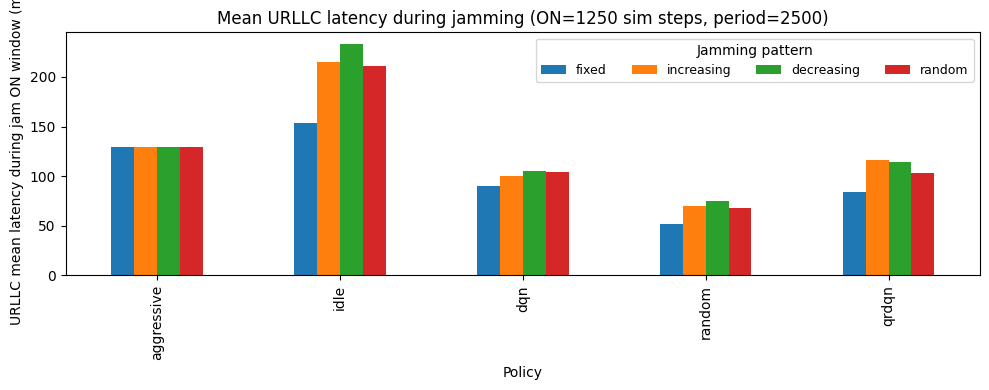

/tmp/ipykernel_966323/2489809935.py:305: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  thr_pivot = summary_df.pivot_table(index="policy", columns="pattern", values="jam_thr_mbps", aggfunc="mean")


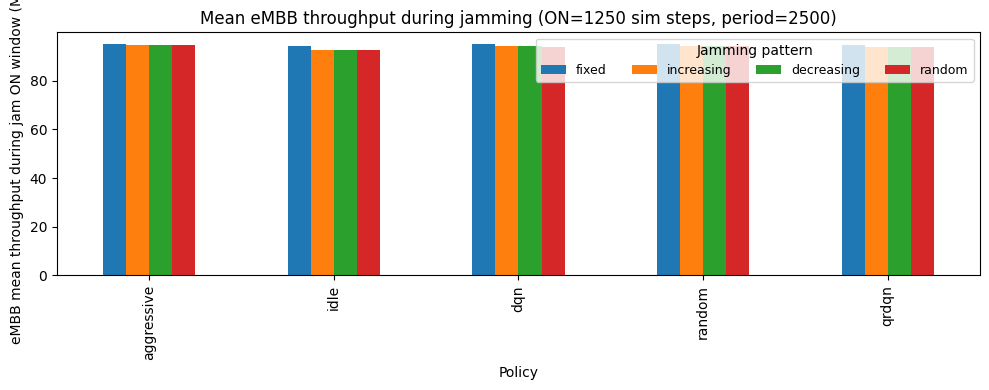


[OK] Saved CSV + plots to: /home/elahe/user/elahe/RL_work/Resilient_PRB_allocation/backend/tb_logs/res_validator/_plots


<Figure size 1000x400 with 0 Axes>

<Figure size 1000x400 with 0 Axes>

In [23]:
#!/usr/bin/env python3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing import event_accumulator

# -----------------------------
# User settings
# -----------------------------
ROOT = Path("../../tb_logs/res_validator")  # <-- change if needed

POLICIES = ["aggressive", "idle", "dqn", "random", "qrdqn"]
PATTERNS = ["fixed", "increasing", "decreasing", "random"]

JAM_THRESHOLD = 0.999
DEADLINE_MS = 1.0

# Your jammer (SIM steps)
JAM_ON_STEPS_SIM = 1250
JAM_PERIOD_STEPS_SIM = 2500

PRE_STEPS = 0
POST_EXTRA = 0

# -----------------------------
# Helpers
# -----------------------------
def infer_tb_step_stride(steps: np.ndarray) -> int:
    if steps is None or len(steps) < 3:
        return 1
    d = np.diff(np.asarray(steps, dtype=int))
    d = d[d > 0]
    if len(d) == 0:
        return 1
    return max(1, int(np.median(d)))

def sim_to_tb_steps(sim_steps: int, tb_stride: int) -> int:
    return int(np.ceil(sim_steps / float(tb_stride)))

def merge_asof_by_step(base: pd.DataFrame, other: pd.DataFrame, tolerance: int) -> pd.DataFrame:
    if other is None or other.empty:
        return base
    a = base.sort_values("step").copy()
    b = other.sort_values("step").copy()
    merged = pd.merge_asof(a, b, on="step", direction="nearest", tolerance=tolerance, suffixes=("", "_y"))
    if "wall_time_y" in merged.columns and "wall_time" in merged.columns:
        merged.drop(columns=["wall_time_y"], inplace=True)
    return merged

def detect_jam_starts(df: pd.DataFrame, min_gap_tb_steps: int) -> list[int]:
    if df.empty or "effective_prb_ratio" not in df.columns:
        return []
    steps = df["step"].to_numpy(dtype=int)
    jammed = (df["effective_prb_ratio"].to_numpy() < JAM_THRESHOLD).astype(np.int32)

    starts = []
    prev = 0
    last_start_step = -10**18
    for i in range(len(jammed)):
        if jammed[i] == 1 and prev == 0:
            s0 = int(steps[i])
            if s0 - last_start_step >= min_gap_tb_steps:
                starts.append(s0)
                last_start_step = s0
        prev = jammed[i]
    return starts

def event_aligned_mean_by_index(df: pd.DataFrame, col: str, start_steps: list[int], pre: int, post: int) -> pd.DataFrame:
    if df.empty or col not in df.columns or not start_steps:
        return pd.DataFrame(columns=["t_rel", "mean", "std", "n"])

    d = df[["step", col]].dropna().sort_values("step").reset_index(drop=True)
    if d.empty:
        return pd.DataFrame(columns=["t_rel", "mean", "std", "n"])

    steps = d["step"].to_numpy(dtype=int)
    vals = d[col].to_numpy(dtype=float)

    t_rels = np.arange(-pre, post, dtype=int)
    aligned = []

    for s0 in start_steps:
        i0 = int(np.searchsorted(steps, s0))
        if i0 >= len(steps):
            i0 = len(steps) - 1
        if i0 > 0 and abs(steps[i0] - s0) > abs(steps[i0 - 1] - s0):
            i0 -= 1

        row = []
        for tr in t_rels:
            i = i0 + tr
            row.append(vals[i] if (0 <= i < len(vals)) else np.nan)
        aligned.append(row)

    A = np.asarray(aligned, dtype=float)

    n = np.sum(np.isfinite(A), axis=0)
    mean = np.full(A.shape[1], np.nan)
    std  = np.full(A.shape[1], np.nan)

    ok = n > 0
    if np.any(ok):
        mean[ok] = np.nanmean(A[:, ok], axis=0)
        std[ok]  = np.nanstd(A[:, ok], axis=0)

    return pd.DataFrame({"t_rel": t_rels, "mean": mean, "std": std, "n": n})

# -----------------------------
# FAST: index event files once
# -----------------------------
def index_event_files_by_policy(root: Path, policies: list[str]) -> dict[str, list[Path]]:
    """
    Returns: policy -> list of event files under that policy (one rglob per policy)
    """
    out = {}
    for pol in policies:
        pdir = root / pol
        if not pdir.exists():
            out[pol] = []
            continue
        evs = list(pdir.rglob("events.out.tfevents.*"))
        # newest first
        evs.sort(key=lambda p: p.stat().st_mtime, reverse=True)
        out[pol] = evs
    return out

def find_event_file_from_index(index: dict[str, list[Path]], policy: str, test_name: str) -> Path | None:
    """
    Uses pre-indexed list. Just scans the list in memory (fast).
    """
    for ev in index.get(policy, []):
        if test_name in str(ev.parent):
            return ev
    return None

# -----------------------------
# FAST: read all tags from ONE Reload
# -----------------------------
def read_scalars_once(event_file: Path, tags: list[str]) -> dict[str, pd.DataFrame]:
    """
    One EventAccumulator Reload, then pull all requested tags.
    Returns dict tag -> DataFrame(step, wall_time, value)
    """
    ea = event_accumulator.EventAccumulator(str(event_file), size_guidance={"scalars": 0})
    ea.Reload()

    available = set(ea.Tags().get("scalars", []))
    out = {}
    for tag in tags:
        if tag not in available:
            out[tag] = pd.DataFrame(columns=["step", "wall_time", "value"])
            continue
        evs = ea.Scalars(tag)
        df = pd.DataFrame(
            {"step": [e.step for e in evs], "wall_time": [e.wall_time for e in evs], "value": [e.value for e in evs]}
        ).sort_values("step")
        out[tag] = df
    return out

def load_one_run_fast(event_file: Path) -> pd.DataFrame | None:
    tags = ["latency/urllc", "throughput/embb_mbps", "prb/effective_ratio", "obs/reserve_used_prb"]
    scal = read_scalars_once(event_file, tags)

    lat = scal["latency/urllc"].rename(columns={"value": "latency_sec"})
    thr = scal["throughput/embb_mbps"].rename(columns={"value": "embb_mbps"})
    prb = scal["prb/effective_ratio"].rename(columns={"value": "effective_prb_ratio"})
    rsv = scal["obs/reserve_used_prb"].rename(columns={"value": "reserve_used_prb"})

    if lat.empty or thr.empty or prb.empty:
        return None

    tb_stride = infer_tb_step_stride(prb["step"].to_numpy())
    tolerance = max(1, tb_stride // 2)

    df = prb.copy()
    df = merge_asof_by_step(df, lat, tolerance=tolerance)
    df = merge_asof_by_step(df, thr, tolerance=tolerance)
    if not rsv.empty:
        df = merge_asof_by_step(df, rsv, tolerance=tolerance)
    else:
        df["reserve_used_prb"] = np.nan

    df["latency_ms"] = df["latency_sec"] * 1000.0
    df["tb_stride"] = tb_stride
    return df

# -----------------------------
# Main
# -----------------------------
print(f"[INFO] Indexing event files under: {ROOT.resolve()}")
ev_index = index_event_files_by_policy(ROOT, POLICIES)
for pol in POLICIES:
    print(f"[INFO] {pol}: {len(ev_index.get(pol, []))} event files found")

aligned_lat = {}
aligned_thr = {}
aligned_eff = {}
summary_rows = []

total_jobs = len(POLICIES) * len(PATTERNS)
job_i = 0

for policy in POLICIES:
    for pat in PATTERNS:
        job_i += 1
        test_name = f"gym_from_testing_config_1ms_10s_8UE_jam_pattern_{pat}"
        ev = find_event_file_from_index(ev_index, policy, test_name)

        print(f"[{job_i}/{total_jobs}] policy={policy:<10} pattern={pat:<10} -> ", end="")
        if ev is None:
            print("NO EVENT FILE")
            summary_rows.append({
                "policy": policy, "pattern": pat, "n_jam_events": 0,
                "tb_stride": np.nan, "jam_on_tb_steps": np.nan, "period_tb_steps": np.nan,
                "jam_lat_ms": np.nan, "violation_pct": np.nan, "jam_thr_mbps": np.nan,
                "jam_reserve_used": np.nan, "event_file": None,
            })
            continue

        print(f"loading {ev.name}")

        df = load_one_run_fast(ev)
        if df is None:
            summary_rows.append({
                "policy": policy, "pattern": pat, "n_jam_events": 0,
                "tb_stride": np.nan, "jam_on_tb_steps": np.nan, "period_tb_steps": np.nan,
                "jam_lat_ms": np.nan, "violation_pct": np.nan, "jam_thr_mbps": np.nan,
                "jam_reserve_used": np.nan, "event_file": str(ev),
            })
            continue

        tb_stride = int(df["tb_stride"].iloc[0])
        jam_on_tb = sim_to_tb_steps(JAM_ON_STEPS_SIM, tb_stride)
        period_tb = sim_to_tb_steps(JAM_PERIOD_STEPS_SIM, tb_stride)

        PRE_TB = PRE_STEPS
        POST_TB = period_tb + POST_EXTRA
        MIN_GAP_TB = max(1, period_tb - 1)

        starts = detect_jam_starts(df, min_gap_tb_steps=MIN_GAP_TB)

        lat_al = event_aligned_mean_by_index(df, "latency_ms", starts, pre=PRE_TB, post=POST_TB)
        thr_al = event_aligned_mean_by_index(df, "embb_mbps", starts, pre=PRE_TB, post=POST_TB)
        eff_al = event_aligned_mean_by_index(df, "effective_prb_ratio", starts, pre=PRE_TB, post=POST_TB)

        aligned_lat[(pat, policy)] = lat_al
        aligned_thr[(pat, policy)] = thr_al
        aligned_eff[(pat, policy)] = eff_al

        # Summary during jam ON window [0, jam_on_tb)
        if not lat_al.empty:
            s = lat_al[(lat_al.t_rel >= 0) & (lat_al.t_rel < jam_on_tb)]["mean"].to_numpy()
            jam_lat_ms = float(np.nanmean(s)) if len(s) else np.nan
            violation_pct = float(np.mean(s > DEADLINE_MS) * 100.0) if len(s) else np.nan
        else:
            jam_lat_ms = np.nan
            violation_pct = np.nan

        if not thr_al.empty:
            s = thr_al[(thr_al.t_rel >= 0) & (thr_al.t_rel < jam_on_tb)]["mean"].to_numpy()
            jam_thr_mbps = float(np.nanmean(s)) if len(s) else np.nan
        else:
            jam_thr_mbps = np.nan

        df["jammed"] = df["effective_prb_ratio"] < JAM_THRESHOLD
        jam_df = df[df["jammed"]]
        jam_reserve_used = float(jam_df["reserve_used_prb"].mean()) if not jam_df.empty else np.nan

        summary_rows.append({
            "policy": policy,
            "pattern": pat,
            "n_jam_events": len(starts),
            "tb_stride": tb_stride,
            "jam_on_tb_steps": jam_on_tb,
            "period_tb_steps": period_tb,
            "jam_lat_ms": jam_lat_ms,
            "violation_pct": violation_pct,
            "jam_thr_mbps": jam_thr_mbps,
            "jam_reserve_used": jam_reserve_used,
            "event_file": str(ev),
        })

summary_df = pd.DataFrame(summary_rows)
summary_df["policy"] = pd.Categorical(summary_df["policy"], categories=POLICIES, ordered=True)
summary_df["pattern"] = pd.Categorical(summary_df["pattern"], categories=PATTERNS, ordered=True)

print("\n=== Summary (head) ===")
print(summary_df.head(10))
print("\n=== Summary (full) ===")
print(summary_df)

# -----------------------------
# Bar charts
# -----------------------------
lat_pivot = summary_df.pivot_table(index="policy", columns="pattern", values="jam_lat_ms", aggfunc="mean")
ax = lat_pivot.plot(kind="bar", figsize=(10, 4))
ax.set_ylabel("URLLC mean latency during jam ON window (ms)")
ax.set_xlabel("Policy")
ax.set_title("Mean URLLC latency during jamming (ON=1250 sim steps, period=2500)")
ax.legend(title="Jamming pattern", ncols=4, fontsize=9)
plt.tight_layout()
plt.show()

thr_pivot = summary_df.pivot_table(index="policy", columns="pattern", values="jam_thr_mbps", aggfunc="mean")
ax = thr_pivot.plot(kind="bar", figsize=(10, 4))
ax.set_ylabel("eMBB mean throughput during jam ON window (Mbps)")
ax.set_xlabel("Policy")
ax.set_title("Mean eMBB throughput during jamming (ON=1250 sim steps, period=2500)")
ax.legend(title="Jamming pattern", ncols=4, fontsize=9)
plt.tight_layout()
plt.show()

# Save outputs
OUT_DIR = ROOT / "_plots"
OUT_DIR.mkdir(parents=True, exist_ok=True)
summary_df.to_csv(OUT_DIR / "summary_latency_throughput.csv", index=False)

plt.figure(figsize=(10, 4))
ax = lat_pivot.plot(kind="bar")
ax.set_ylabel("URLLC mean latency during jam ON window (ms)")
ax.set_xlabel("Policy")
ax.set_title("Mean URLLC latency during jamming (ON=1250 sim steps, period=2500)")
ax.legend(title="Jamming pattern", ncols=4, fontsize=9)
plt.tight_layout()
plt.savefig(OUT_DIR / "barchart_latency_ms.png", dpi=200)
plt.close()

plt.figure(figsize=(10, 4))
ax = thr_pivot.plot(kind="bar")
ax.set_ylabel("eMBB mean throughput during jam ON window (Mbps)")
ax.set_xlabel("Policy")
ax.set_title("Mean eMBB throughput during jamming (ON=1250 sim steps, period=2500)")
ax.legend(title="Jamming pattern", ncols=4, fontsize=9)
plt.tight_layout()
plt.savefig(OUT_DIR / "barchart_throughput_mbps.png", dpi=200)
plt.close()

print(f"\n[OK] Saved CSV + plots to: {OUT_DIR.resolve()}")


In [26]:
from pathlib import Path
from collections import defaultdict
import re
import numpy as np
import pandas as pd

from tensorflow.python.lib.io import tf_record
from tensorboard.compat.proto.event_pb2 import Event

# ============================================================
# CONFIG
# ============================================================
ROOT = Path("../../tb_logs/res_validator")  # <-- change if needed

POLICIES = ["aggressive", "idle", "dqn", "qrdqn", "random"]

JAM_TAG = "prb/effective_ratio"
METRIC_TAGS = [
    "latency/urllc",
    "throughput/urllc",
    "throughput/embb_mbps",
]

EPISODE_DECISION_STEPS = 1000
EPISODE_COUNT = 50
DECISION_TO_SIM_STEPS = 10  # 10 sim steps per decision step

JAM_THRESHOLD = 0.999
GAP_TOLERANCE = 2
MIN_JAM_LEN = 5

ABS_TOL = 1e-6
REL_TOL = 0.01
X_AT_JAM_START = True


# ============================================================
# Parsing policy/power/pattern/baseline from folder name
# ============================================================
def parse_run_metadata(policy: str, run_folder_name: str):
    """
    Examples:
      gym_from_testing_config_1ms_10s_8UE_jam_fixed_5        -> power=5,  pattern="fixed"
      gym_from_testing_config_1ms_10s_8UE_jam_pattern_random -> pattern="random"
      gym_from_testing_config_1ms_10s_8UE_jam_fixed_baseline_0 -> baseline=True, pattern="baseline"
    """
    name = run_folder_name.lower()

    # baseline?
    baseline = bool(re.search(r"baseline", name))

    # pattern: jam_pattern_<pattern>
    pattern = None
    m = re.search(r"jam_pattern_([a-z]+)", name)
    if m:
        pattern = m.group(1)

    # fixed-power: jam_fixed_<power>
    power = None
    m2 = re.search(r"jam_fixed_(\d+)", name)
    if m2:
        power = int(m2.group(1))
        # If it’s "jam_fixed_5", pattern is basically "fixed" (unless you want to keep it separate)
        if pattern is None and not baseline:
            pattern = "fixed"

    # If baseline run and no pattern, mark pattern as "baseline"
    if baseline and pattern is None:
        pattern = "baseline"

    return {
        "policy": policy,
        "run": run_folder_name,
        "pattern": pattern,
        "power": power,
        "baseline": baseline,
    }


# ============================================================
# TB event parsing
# ============================================================
def read_scalar_events(event_file: Path, wanted_tags: set):
    out = defaultdict(list)
    for rec in tf_record.tf_record_iterator(str(event_file)):
        e = Event()
        e.ParseFromString(rec)
        if not e.summary or not e.summary.value:
            continue
        step = int(e.step)
        for v in e.summary.value:
            if v.tag in wanted_tags:
                out[v.tag].append((step, float(v.simple_value)))
    for tag in out:
        out[tag].sort(key=lambda x: x[0])
    return out


def to_step_aligned_series(pairs, index_min, index_max):
    if not pairs:
        return pd.Series(index=np.arange(index_min, index_max + 1), dtype=float)
    df = pd.DataFrame(pairs, columns=["step", "value"]).drop_duplicates("step", keep="last")
    s = pd.Series(df["value"].values, index=df["step"].values).sort_index()
    full_idx = np.arange(index_min, index_max + 1)
    return s.reindex(full_idx).ffill()


# ============================================================
# Jam detection helpers
# ============================================================
def fill_small_gaps(is_jam: np.ndarray, gap_tol: int):
    if gap_tol <= 0:
        return is_jam
    x = is_jam.copy()
    n = len(x)
    i = 0
    while i < n:
        if x[i]:
            i += 1
            continue
        j = i
        while j < n and (not x[j]):
            j += 1
        gap_len = j - i
        left_true = (i - 1 >= 0 and x[i - 1])
        right_true = (j < n and x[j])
        if left_true and right_true and gap_len <= gap_tol:
            x[i:j] = True
        i = j
    return x


def extract_intervals(is_jam: np.ndarray, min_len: int):
    intervals = []
    n = len(is_jam)
    i = 0
    while i < n:
        if not is_jam[i]:
            i += 1
            continue
        s = i
        while i < n and is_jam[i]:
            i += 1
        e = i - 1
        if (e - s + 1) >= min_len:
            intervals.append((s, e))
    return intervals


# ============================================================
# Recovery
# ============================================================
def within_tol(val, ref, abs_tol, rel_tol):
    if np.isnan(val) or np.isnan(ref):
        return False
    return abs(val - ref) <= max(abs_tol, rel_tol * max(1.0, abs(ref)))


def compute_recovery(metric: np.ndarray, js: int, je: int, next_js: int | None):
    n = len(metric)

    if X_AT_JAM_START:
        X = metric[js]
    else:
        X = metric[js - 1] if js - 1 >= 0 else metric[js]

    Y = metric[je]

    search_start = je + 1
    search_end = (next_js - 1) if next_js is not None else (n - 1)

    recovered = False
    recovery_steps = np.nan
    end_value_before_next_jam = np.nan

    if search_start <= search_end:
        end_value_before_next_jam = metric[search_end]
        for t in range(search_start, search_end + 1):
            if within_tol(metric[t], X, ABS_TOL, REL_TOL):
                recovered = True
                recovery_steps = t - search_start
                break

    return X, Y, recovered, recovery_steps, end_value_before_next_jam


# ============================================================
# Discover event files with metadata
# ============================================================
def iter_policy_runs():
    """
    Yields (policy, run_folder_path, event_file_path)
    """
    for policy in POLICIES:
        policy_dir = ROOT / policy
        if not policy_dir.exists():
            continue
        # run folders directly under policy
        for run_dir in sorted([p for p in policy_dir.iterdir() if p.is_dir()]):
            # each run_dir likely contains 1 event file (maybe multiple)
            for evf in sorted(run_dir.glob("events.out.tfevents*")):
                yield policy, run_dir, evf


# ============================================================
# Main
# ============================================================
def run_all():
    wanted_tags = set([JAM_TAG] + METRIC_TAGS)
    rows = []

    for policy, run_dir, evf in iter_policy_runs():
        meta = parse_run_metadata(policy, run_dir.name)

        data = read_scalar_events(evf, wanted_tags)
        if JAM_TAG not in data or len(data[JAM_TAG]) == 0:
            print(f"[WARN] missing {JAM_TAG} in {evf}")
            continue

        steps = [s for s, _ in data[JAM_TAG]]
        gmin, gmax = min(steps), max(steps)

        jam_s = to_step_aligned_series(data[JAM_TAG], gmin, gmax)
        metric_series = {}
        for tag in METRIC_TAGS:
            metric_series[tag] = to_step_aligned_series(data.get(tag, []), gmin, gmax)

        jam_vals = jam_s.values
        is_jam = jam_vals < JAM_THRESHOLD
        is_jam = fill_small_gaps(is_jam, GAP_TOLERANCE)

        # episode split
        for ep in range(EPISODE_COUNT):
            ep_start = ep * EPISODE_DECISION_STEPS
            ep_end = ep_start + EPISODE_DECISION_STEPS
            if ep_start >= len(is_jam):
                break
            ep_end = min(ep_end, len(is_jam))

            ep_is_jam = is_jam[ep_start:ep_end]
            intervals = extract_intervals(ep_is_jam, MIN_JAM_LEN)

            for metric_tag in METRIC_TAGS:
                ms = metric_series[metric_tag].values[ep_start:ep_end]

                for j_idx, (js, je) in enumerate(intervals):
                    next_js = intervals[j_idx + 1][0] if (j_idx + 1 < len(intervals)) else None

                    X, Y, recovered, rec_steps, end_val = compute_recovery(ms, js, je, next_js)

                    rows.append({
                        **meta,
                        "event_file": str(evf),

                        "episode": ep,
                        "jam_idx": j_idx,
                        "jam_start_dec": int(js),
                        "jam_end_dec": int(je),
                        "jam_len_dec": int(je - js + 1),

                        "metric": metric_tag,
                        "X": float(X) if not np.isnan(X) else np.nan,
                        "Y": float(Y) if not np.isnan(Y) else np.nan,
                        "recovered": bool(recovered),

                        "recovery_steps_dec": float(rec_steps) if not np.isnan(rec_steps) else np.nan,
                        "recovery_steps_sim": (rec_steps * DECISION_TO_SIM_STEPS
                                               if not np.isnan(rec_steps) else np.nan),

                        "end_value_before_next_jam": float(end_val) if not np.isnan(end_val) else np.nan,
                    })

    return pd.DataFrame(rows)


df = run_all()
print("rows:", len(df))
display(df.head(20))

out_csv = ROOT / "recovery_summary_with_power_pattern.csv"
df.to_csv(out_csv, index=False)
print("Saved:", out_csv)

# quick check: how many jams per episode?
if len(df) > 0:
    jams_per_ep = df.groupby(["policy","run","episode"])["jam_idx"].nunique().reset_index(name="num_jams")
    display(jams_per_ep.groupby(["policy","run"])["num_jams"].describe())


rows: 0


""


Saved: ../../tb_logs/res_validator/recovery_summary_with_power_pattern.csv
